# 02 - The Jacobian of the full scan, and three ways to diagonalize it

Notebook 00 built the local Jacobian $A_R$ at a single probe position and notebook 01
studied it. This notebook stacks every position of a scan into the one operator the
measurement actually realises, and extracts its object-space modes **three different
ways**, so that the answer can be separated from the algorithm used to obtain it.

The question the operator answers is: *which changes to the specimen would this scan have
seen, and which would it have missed entirely?*

## The forward model and the symbols used throughout

In a 4D-STEM scan the diffraction pattern recorded at probe position
$\mathbf R = (R_x, R_y)$ is

$$I_{\mathbf R}(\mathbf k) = \left|\mathcal F\left[P(\mathbf r - \mathbf R)\,O(\mathbf r)\right]\right|^2
= \left|\mathcal F\left[P_{\mathbf R} O\right]\right|^2 .$$

A faint excitation perturbs the object in phase only, $O_{\mathrm{on}} = O_0 e^{j\Delta\varphi}$
with $O_0 = T e^{j\varphi_{\mathrm{off}}}$ the base state and $\Delta\varphi$ real. Assuming
$|\Delta\varphi| \ll 1$ radian, so that $e^{j\Delta\varphi} \approx 1 + j\Delta\varphi$,
the detector-plane wave separates into a base term and a perturbation term,

$$\Psi_{\mathrm{on},\mathbf R} = \mathcal F\{P_{\mathbf R}O_0\} + j\,\mathcal F\{P_{\mathbf R}O_0\,\Delta\varphi\}
 = \Psi_{0,\mathbf R} + j\Psi_{\Delta,\mathbf R},$$

and the first-order change in the recorded intensity is

$$\Delta I_{\mathbf R}(\mathbf k) = -2\,\mathrm{Im}\!\left[\Psi_{0,\mathbf R}^{*}(\mathbf k)\,
\mathcal F\{\psi_{0,\mathbf R}\Delta\varphi\}(\mathbf k)\right] \;=\; \left[A_{\mathbf R}\Delta\varphi\right](\mathbf k).$$

This is a derivative of the *predicted* intensity with respect to the excitation, not a
subtraction of two measured patterns; nothing below requires light-on and light-off data
at the same probe position.

| symbol | meaning |
|---|---|
| $O_0$ | the base object, a pure phase object on the object grid |
| $h$ | a small **real** phase perturbation of it, so the perturbed object is $O_0 e^{jh}$ |
| $\mathbf R$ | one scan position; the scan has $M$ of them |
| $P_{\mathbf R}$ | the probe, centred at $\mathbf R$ |
| $\psi_{0,\mathbf R} = P_{\mathbf R}O_0$ | the **exit wave** at that position, on the object grid |
| $\mathcal F$ | the centred 2-D DFT, $\mathrm{fftshift}\circ\mathrm{fft2}\circ\mathrm{ifftshift}$ |
| $\mathrm{crop}$ | keep the central detector pixels - what `max_angle="valid"` returns |
| $\Psi_{0,\mathbf R} = \mathrm{crop}\,\mathcal F\{\psi_{0,\mathbf R}\}$ | the **camera wave**; the recorded intensity is $|\Psi_{0,\mathbf R}|^2$ |
| $N$ | object pixels; $D$ | detector pixels per pattern |

Writing the transform as a matrix and the pointwise products as diagonal matrices
$D_x = \mathrm{diag}(x)$, the operator at one position is

$$A_{\mathbf R} = -2\,\mathrm{Im}\left\{D_{\Psi_{0,\mathbf R}^{*}}\,F\,D_{\psi_{0,\mathbf R}}\right\},$$

which is a real matrix acting on $\Delta\varphi$ precisely because $\Delta\varphi$ is real.
The base object and the probe enter only through the product $\psi_{0,\mathbf R}=P_{\mathbf R}O_0$,
which is why a thick specimen is accommodated simply by replacing the exit wave with a
multislice one (notebook 04).

## Stacking the scan

A ptychographic measurement is every pattern at once, so the operator of the experiment is
the row-stack of the per-position ones,

$$I_{4D} = A\,\Delta\varphi, \qquad
A = \begin{bmatrix} A_{\mathbf R_1} \\ A_{\mathbf R_2} \\ \vdots \\ A_{\mathbf R_M}\end{bmatrix}
\in \mathbb{R}^{SM \times N}.$$

$A$ has one row per (scan position, detector pixel) and one column per object pixel.
Stacking rows is the right operation because the positions are independent measurements of
the same object: their responses add in the least-squares sense, which is what the stack
encodes.

## What its decomposition means

Take $A = U\Sigma V^{\mathsf T}$ and read it right to left on a perturbation $A\Delta\varphi$:
$V^{\mathsf T}$ projects the phase onto an orthogonal set of **phase modes**, the natural
basis in which this experiment responds; $\Sigma$ gives each mode its magnitude, so a
larger $\sigma_i$ means the mode is expressed more strongly in the data; and $U$ carries
each phase mode to the change it produces in the diffraction patterns. Consequently

* $v_1$ is the perturbation this experiment is most sensitive to;
* a mode whose $\sigma_i$ has collapsed is one the experiment barely responds to;
* the null space of $A$ is, to linear order, exactly what this scan **cannot measure at
  all** - no reconstruction algorithm can recover it, because nothing in the data depends
  on it.

$A$ is far too large to decompose directly: $SM \approx 6\times10^6$ rows here. The standard
device is to work with the Gram matrix instead,

$$A^{\mathsf T}A = \left(U\Sigma V^{\mathsf T}\right)^{\mathsf T} U\Sigma V^{\mathsf T}
= V\Sigma^{2}V^{\mathsf T},$$

which is only $N \times N$ - the size of the object - and whose eigenvectors are exactly the
right singular vectors of $A$, with eigenvalues $\sigma_i^2$. It also decomposes over the
scan, so it can be accumulated one position at a time:

$$A^{\mathsf T}A = \sum_{\mathbf R} A_{\mathbf R}^{\mathsf T}A_{\mathbf R}.$$

## What this notebook compares

Forming $A^{\mathsf T}A$ is not the only option, and it is not free: squaring the operator
squares its condition number, so the small end of the spectrum is reported in half the
digits it was computed with. The three sections below take three different routes to the
same modes and are compared against each other at the end.

| | domain | Gram formed? | diagonalization | returns |
|---|---|---|---|---|
| **A** | full field, $N = $ all object pixels | yes, densely | subspace iteration on the explicit $A^{\mathsf T}A$ | top $k$ modes |
| **B** | a window inside the scanned region | yes, via FFT identities | full `eigh` | **every** mode of the window |
| **C** | full field | **no** | subspace iteration on $A$ and $A^{\mathsf T}$ directly | top $k$ modes |

Two one-sided bounds make the comparison quantitative rather than impressionistic, and both
are checked numerically in the final section:

* **B against A.** The window Gram is literally a principal submatrix of the full-field
  Gram - same object-pixel basis, a subset of the indices. Cauchy's interlacing theorem then
  gives $\lambda_i(B) \le \lambda_i(A)$ for every $i$: restricting the support can only
  *lose* sensitivity, never invent it.
* **C against A.** A Rayleigh-Ritz value computed from a subspace underestimates the true
  eigenvalue, so $\sigma_i(C) \le \sigma_i(A)$ as well, until the iteration converges.

So both alternatives approach the baseline from below, for two different and separately
checkable reasons.

In [1]:
import sys
import hashlib
import pickle
import time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy import ndimage
from scipy.spatial import cKDTree

NOTEBOOK_DIR = Path.cwd()
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

import linearized_jacobian as lj
import fft_structured_gram as fsg

torch.backends.cuda.matmul.allow_tf32 = False   # the Gram needs every bit it can get

print("notebook dir :", NOTEBOOK_DIR)
print("modules      :", lj.__file__)
print("             :", fsg.__file__)
print("torch        :", torch.__version__)
print("cuda device  :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")
if torch.cuda.is_available():
    print("device memory:", f"{torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

notebook dir : /home/rotem/ptycho_light/quantem/scripts/linearized-ptycho
modules      : /home/rotem/ptycho_light/quantem/scripts/linearized-ptycho/linearized_jacobian.py
             : /home/rotem/ptycho_light/quantem/scripts/linearized-ptycho/fft_structured_gram.py
torch        : 2.14.1+cu130
cuda device  : NVIDIA GeForce RTX 5090
device memory: 33.7 GB


## Configuration

The only cell to edit per experiment.

`SCAN_ENDPOINT` matters more than it looks. The simulation cell is periodic, so a scan
built with `endpoint=True` puts its last row and column back on top of its first. Those
positions then enter the stack twice and the corner four times, $A^{\mathsf T}A$ carries
that weight, and the leading modes pile up on the over-counted boundary - which is a
property of the scan bookkeeping, not of the optics. It is left `False`, and the duplicate
check below reports the result.

`GRAM_WINDOW_WIDTH_PX` must keep the window **strictly inside the scanned region**; the
cell after next asserts it.

In [2]:
PHASE_CACHE_PATH = NOTEBOOK_DIR.parent / "bcenters_base_excited_phases_wide_fov.pkl"
PHASE_CACHE_KEY_BASE = "base"

ACC_VOLTAGE_EV = 60e3
PROBE_SEMIANGLE_MRAD = 30.0
PROBE_DEFOCUS_ANG = 0.0
SLICE_THICKNESS_ANG = 1.0          # bookkeeping slice for a projected phase object
HBN_LATTICE_CONSTANT_ANG = 2.504   # in-plane a of hexagonal BN; annotation and the atom check only

# Atomic columns are detected from the projected phase (the cache stores no coordinates).
ATOM_PEAK_FOOTPRINT_PX = 11        # smaller than the B-N bond, so neighbours stay separate
ATOM_PEAK_THRESHOLD_FRACTION = 0.15

SCAN_STEP_SIZE_ANG = 0.5           # requested step; GridScan rounds it to fit the extent
SCAN_REGION_START = (7.0, 7.0)     # bottom-left corner of the scanned region [Angstrom]
SCAN_REGION_END = (17.0, 17.0)     # top-right corner
SCAN_ENDPOINT = False

TORCH_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# --- method A: dense full-field Gram -------------------------------------------
# float32 is forced by memory: a float64 Gram on the full grid is 31.8 GB and the dense
# route needs the Kronecker operator beside it.  See the section text.
DENSE_PRECISION = "float32"
DENSE_GRAM_ROW_BLOCK = 4096        # object rows of the Gram updated per GEMM
DENSE_N_MODES = 1024               # modes kept
DENSE_N_OVERSAMPLE = 256           # extra sketch vectors, discarded after the Ritz step
DENSE_N_ITERATIONS = 20
DENSE_USE_CACHE = True             # reuse a saved spectrum when every input below matches
DENSE_CACHE_DIR = NOTEBOOK_DIR / "data"

# --- method B: windowed structured Gram ----------------------------------------
GRAM_WINDOW_WIDTH_PX = 94          # square window of object pixels, centred on the field of view
                                   # (the cell below prints the largest value that still fits)
WINDOW_PRECISION = "float64"       # the window is small enough to afford it
GRAM_ROW_BLOCK = 2048
GRAM_SYMMETRIC = True              # compute the lower triangle only and mirror it

# --- method C: matrix-free, full field -----------------------------------------
FREE_N_MODES = 1024
FREE_N_OVERSAMPLE = 256
FREE_N_ITERATIONS = 20
FREE_SCAN_CHUNK = 2                # scan positions whose detector response is held at once

RANDOM_SEED = 0
N_MODES_SHOWN = 6                  # panels per mode figure
SIGMA_THRESHOLDS = (0.5, 0.1)      # sigma_i / sigma_1 cuts used for the mode-sum spectra

print("device                     :", TORCH_DEVICE)
print("phase cache                :", PHASE_CACHE_PATH.name)
print("requested scan step [A]    :", SCAN_STEP_SIZE_ANG)
print("scan region [A]            :", SCAN_REGION_START, "to", SCAN_REGION_END)
print("A: dense full field        :", DENSE_PRECISION, f"top {DENSE_N_MODES} modes")
print("B: window [object px]      :", GRAM_WINDOW_WIDTH_PX, WINDOW_PRECISION, "(complete spectrum)")
print("C: matrix-free full field  :", f"top {FREE_N_MODES} modes")

device                     : cuda
phase cache                : bcenters_base_excited_phases_wide_fov.pkl
requested scan step [A]    : 0.5
scan region [A]            : (7.0, 7.0) to (17.0, 17.0)
A: dense full field        : float32 top 1024 modes
B: window [object px]      : 94 float64 (complete spectrum)
C: matrix-free full field  : top 1024 modes


## The base state, the probe and the scan

Built here from the cached phase so that the probe settings and the scan are parameters of
this notebook rather than properties of a saved file. Only the **base** object enters the
operator - the Jacobian is a derivative evaluated at the base state and never sees the
excitation.

The exit and camera waves are carried in complex128 throughout. The inputs themselves are
float32 (that is what abTEM returns), so this does not make the *model* more accurate; it
means that the accumulation of $\sum_{\mathbf R} A_{\mathbf R}^{\mathsf T}A_{\mathbf R}$,
which is where digits are actually lost, is not the limiting factor except where a method
deliberately drops to float32.

One transform convention is used for both factors of $A_{\mathbf R}$. The centred
$\mathrm{fftshift}\circ\mathrm{fft2}\circ\mathrm{ifftshift}$ differs from the corner-origin
$\mathrm{fftshift}\circ\mathrm{fft2}$ by a phase ramp across the detector, and that ramp
cancels inside $A_{\mathbf R}$ **only if the same convention is used for
$\Psi_{0,\mathbf R}$ and for $\mathcal F\{\psi_{0,\mathbf R}h\}$**. Mixing the two silently
produces a different operator, so the transform is defined once here and reused everywhere.

In [3]:
with open(PHASE_CACHE_PATH, "rb") as handle:
    phase_cache = pickle.load(handle)

phase_base = np.asarray(phase_cache[PHASE_CACHE_KEY_BASE], dtype=np.float32)
object_x_ang = np.asarray(phase_cache["x"], dtype=np.float32); object_x_ang -= object_x_ang[0]
object_y_ang = np.asarray(phase_cache["y"], dtype=np.float32); object_y_ang -= object_y_ang[0]
object_sampling_ang = (float(object_y_ang[1] - object_y_ang[0]),
                       float(object_x_ang[1] - object_x_ang[0]))
object_base = np.exp(1j * phase_base).astype(np.complex64)

potential = lj.make_phase_potential(
    phase_base, ACC_VOLTAGE_EV, SLICE_THICKNESS_ANG, object_sampling_ang
)
probe = lj.make_probe(ACC_VOLTAGE_EV, PROBE_SEMIANGLE_MRAD, PROBE_DEFOCUS_ANG, potential)

n_object_y, n_object_x = phase_base.shape
n_object_pixels = n_object_y * n_object_x
field_of_view_ang = tuple(float(v) for v in potential.extent)
detector_shape = lj.valid_detector_shape(probe)
n_detector_y, n_detector_x = detector_shape
n_detector_pixels = n_detector_y * n_detector_x
detector_sampling_inv_ang = (1.0 / field_of_view_ang[1], 1.0 / field_of_view_ang[0])
electron_wavelength_ang = float(probe.wavelength)

scan_positions_xy_ang = lj.grid_scan_positions_ang(
    potential, SCAN_STEP_SIZE_ANG, endpoint=SCAN_ENDPOINT,
    start=SCAN_REGION_START, end=SCAN_REGION_END,
)
scan_shape = scan_positions_xy_ang.shape[:2]
scan_positions_flat_xy_ang = scan_positions_xy_ang.reshape(-1, 2).astype(np.float64)
n_scan_positions = len(scan_positions_flat_xy_ang)
realised_scan_step_ang = float(np.diff(np.unique(scan_positions_flat_xy_ang[:, 0]))[0])

# Two positions that coincide modulo the periodic cell are one measurement counted twice.
scan_positions_wrapped_ang = np.round(
    np.mod(np.round(scan_positions_flat_xy_ang / np.array(field_of_view_ang), 6), 1.0)
    * np.array(field_of_view_ang), 4
)
n_distinct_scan_positions = len(np.unique(scan_positions_wrapped_ang, axis=0))

probe_by_scan = torch.as_tensor(
    np.asarray(probe.build(scan=scan_positions_flat_xy_ang.tolist()).compute().array
               ).astype(np.complex64),
    device=TORCH_DEVICE,
)
object_base_torch = torch.as_tensor(object_base, device=TORCH_DEVICE)
exit_wave_by_scan = (probe_by_scan * object_base_torch).to(torch.complex128)


def centered_dft_torch(array):
    '''``fftshift(fft2(ifftshift(.)))`` over the last two axes - ``lj.centered_dft``, on torch.'''
    return torch.fft.fftshift(
        torch.fft.fft2(torch.fft.ifftshift(array, dim=(-2, -1))), dim=(-2, -1)
    )


detector_row_start = (n_object_y - n_detector_y) // 2
detector_col_start = (n_object_x - n_detector_x) // 2


def crop_to_detector(array):
    '''Keep the central ``detector_shape`` pixels - what max_angle="valid" returns.'''
    return array[..., detector_row_start:detector_row_start + n_detector_y,
                 detector_col_start:detector_col_start + n_detector_x]


camera_wave_by_scan = crop_to_detector(centered_dft_torch(exit_wave_by_scan))

object_extent_ang = [float(object_x_ang[0]), float(object_x_ang[-1]),
                     float(object_y_ang[0]), float(object_y_ang[-1])]
dense_stack_shape = (n_scan_positions * n_detector_pixels, n_object_pixels)

print("exit waves                 :", tuple(exit_wave_by_scan.shape), exit_wave_by_scan.dtype)
print("camera waves               :", tuple(camera_wave_by_scan.shape), camera_wave_by_scan.dtype)
print("object grid [px]           :", (n_object_y, n_object_x), f"= {n_object_pixels:,} pixels")
print("object sampling [A/px]     :", tuple(round(v, 5) for v in object_sampling_ang))
print("field of view [A]          :", tuple(round(v, 3) for v in field_of_view_ang))
print("detector [px]              :", detector_shape, f"= {n_detector_pixels:,} pixels")
print("detector sampling [1/A]    :", tuple(round(v, 5) for v in detector_sampling_inv_ang))
print("wavelength [A]             :", round(electron_wavelength_ang, 5))
print("scan                       :", scan_shape, f"= {n_scan_positions} positions "
      f"at {realised_scan_step_ang:.3f} A")
print("distinct modulo the cell   :", n_distinct_scan_positions,
      "(duplicates:", n_scan_positions - n_distinct_scan_positions, ")")
print(f"stacked operator A         : {dense_stack_shape[0]:,} x {dense_stack_shape[1]:,}"
      f"   ({4 * dense_stack_shape[0] * dense_stack_shape[1] / 1e12:.1f} TB as float32 - "
      f"never formed)")
print(f"Gram A^T A                 : {n_object_pixels:,} x {n_object_pixels:,}"
      f"   ({4 * n_object_pixels ** 2 / 1e9:.1f} GB float32, "
      f"{8 * n_object_pixels ** 2 / 1e9:.1f} GB float64)")

exit waves                 : (400, 251, 251) torch.complex128
camera waves               : (400, 119, 119) torch.complex128
object grid [px]           : (251, 251) = 63,001 pixels
object sampling [A/px]     : (0.096, 0.096)
field of view [A]          : (24.096, 24.096)
detector [px]              : (119, 119) = 14,161 pixels
detector sampling [1/A]    : (0.0415, 0.0415)
wavelength [A]             : 0.04866
scan                       : (20, 20) = 400 positions at 0.500 A
distinct modulo the cell   : 400 (duplicates: 0 )
stacked operator A         : 5,664,400 x 63,001   (1.4 TB as float32 - never formed)
Gram A^T A                 : 63,001 x 63,001   (15.9 GB float32, 31.8 GB float64)


## The probe and the scan, before anything is read off a spectrum

The whole operator is built from these two things. A mode figure can look structured while
the probe behind it is wrong, and no object-space quantity will say so.

The coverage map $\sum_{\mathbf R}|P_{\mathbf R}|^2$ is how much illumination each object
pixel receives over the whole scan. A focused probe stepped more coarsely than its own
width leaves this ragged, and a ragged coverage map puts structure at the scan period into
every mode. The max/min ratio printed beside the panel is the honest statement of how much
of the spectrum belongs to the sampling rather than to the optics.

The same panel settles a question that matters for method B: whether a given window sits in
a uniformly illuminated part of the field. Inside the scanned region the coverage is flat
to within the scan-step ripple; outside it falls away with the probe tails.

atomic columns detected    : 219
median nn spacing          : 1.440 A   (hBN bond a/sqrt(3) = 1.446 A, -0.4%)
probe FWHM, measured : 0.839 A   (ideal Airy 0.51 lambda/alpha : 0.834 A, +0.6%)
scan step            : 0.500 A  =  0.60 x the probe FWHM
coverage max/min over the whole grid : 2060.1


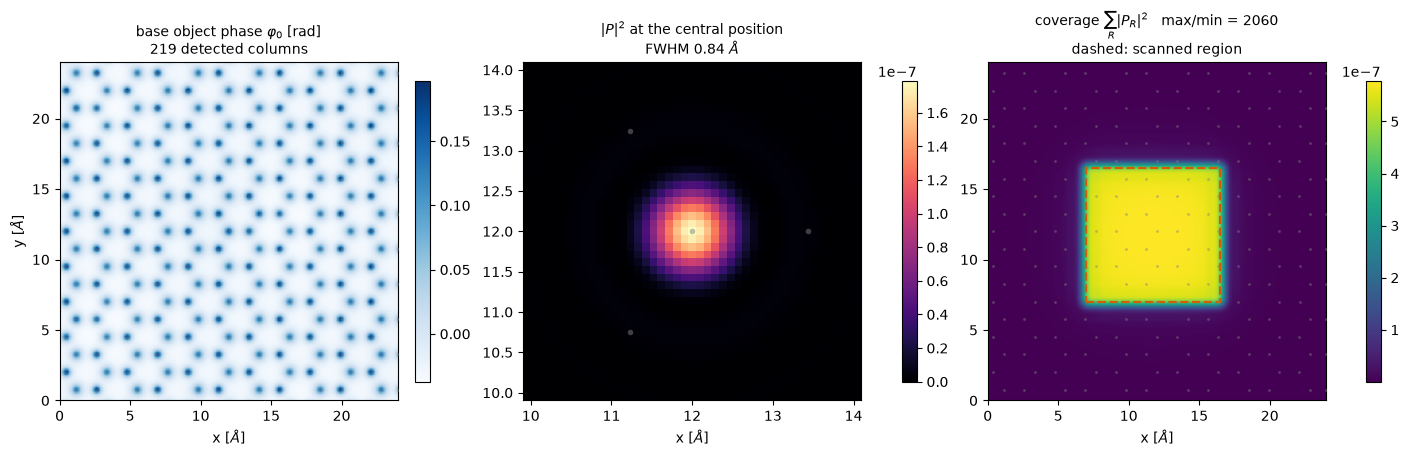

In [4]:
# Atomic columns, detected from the projected phase rather than read from a structure
# file: the phase cache stores only the image.  A column is a local maximum of the
# projected potential, so a maximum filter over a footprint narrower than the B-N bond
# separates neighbours.  What comes out is checked against the hBN bond length below -
# if the median spacing of the detected peaks is not the bond length, the peaks are not
# the lattice and the overlay would be decoration rather than information.
local_maximum = ndimage.maximum_filter(phase_base, size=ATOM_PEAK_FOOTPRINT_PX, mode="wrap")
peak_threshold = phase_base.min() + ATOM_PEAK_THRESHOLD_FRACTION * np.ptp(phase_base)
atom_rows, atom_cols = np.nonzero((phase_base == local_maximum) & (phase_base > peak_threshold))
atom_x_ang = object_x_ang[atom_cols]
atom_y_ang = object_y_ang[atom_rows]

atom_xy_ang = np.c_[atom_x_ang, atom_y_ang]
atom_nn_spacing_ang = float(np.median(
    cKDTree(atom_xy_ang).query(atom_xy_ang, k=2)[0][:, 1]
))
hbn_bond_length_ang = HBN_LATTICE_CONSTANT_ANG / np.sqrt(3.0)


def draw_atoms(ax, markersize=2.0, alpha=0.45, color="#808080"):
    '''Overlay the detected atomic columns, faintly.

    Drawn after the image and with the axis limits restored, so adding them never
    changes what a panel shows - they locate features against the lattice without
    competing with the quantity underneath.
    '''
    x_limits, y_limits = ax.get_xlim(), ax.get_ylim()
    ax.plot(atom_x_ang, atom_y_ang, linestyle="none", marker="o", markersize=markersize,
            markerfacecolor=color, markeredgecolor="none", alpha=alpha, zorder=5)
    ax.set_xlim(x_limits); ax.set_ylim(y_limits)


print(f"atomic columns detected    : {len(atom_x_ang)}")
print(f"median nn spacing          : {atom_nn_spacing_ang:.3f} A"
      f"   (hBN bond a/sqrt(3) = {hbn_bond_length_ang:.3f} A,"
      f" {atom_nn_spacing_ang / hbn_bond_length_ang - 1:+.1%})")

probe_centre_index = int(np.argmin(np.linalg.norm(
    scan_positions_flat_xy_ang - np.array(field_of_view_ang) / 2.0, axis=1
)))
probe_centre_intensity = (probe_by_scan[probe_centre_index].abs() ** 2).cpu().numpy()
coverage = (probe_by_scan.abs() ** 2).sum(0).cpu().numpy()

# Probe width, measured rather than taken from the Airy formula: azimuthal average of
# |P|^2 about the peak pixel in half-pixel bins, interpolated for the half-maximum crossing.
peak_row, peak_col = np.unravel_index(np.argmax(probe_centre_intensity),
                                      probe_centre_intensity.shape)
row_index, col_index = np.mgrid[0:n_object_y, 0:n_object_x]
radius_from_peak_ang = np.hypot((row_index - peak_row) * object_sampling_ang[0],
                                (col_index - peak_col) * object_sampling_ang[1])
radial_bin_width_ang = object_sampling_ang[0] / 2.0
radial_bin_index = (radius_from_peak_ang / radial_bin_width_ang).astype(int).ravel()
radial_bin_count = np.bincount(radial_bin_index)
radial_bin_sum = np.bincount(radial_bin_index, weights=probe_centre_intensity.ravel())
occupied = radial_bin_count > 0
radial_profile = radial_bin_sum[occupied] / radial_bin_count[occupied]
radial_bin_centre_ang = ((np.arange(len(radial_bin_count)) + 0.5) * radial_bin_width_ang)[occupied]

half_maximum = radial_profile.max() / 2.0
first_below = int(np.argmax(radial_profile < half_maximum))
probe_fwhm_ang = 2.0 * float(np.interp(
    half_maximum,
    [radial_profile[first_below], radial_profile[first_below - 1]],
    [radial_bin_centre_ang[first_below], radial_bin_centre_ang[first_below - 1]],
))
airy_fwhm_ang = 0.514 * electron_wavelength_ang / (PROBE_SEMIANGLE_MRAD * 1e-3)

scan_box_ang = [float(scan_positions_flat_xy_ang[:, 0].min() + object_x_ang[0]),
                float(scan_positions_flat_xy_ang[:, 0].max() + object_x_ang[0]),
                float(scan_positions_flat_xy_ang[:, 1].min() + object_y_ang[0]),
                float(scan_positions_flat_xy_ang[:, 1].max() + object_y_ang[0])]

print(f"probe FWHM, measured : {probe_fwhm_ang:.3f} A"
      f"   (ideal Airy 0.51 lambda/alpha : {airy_fwhm_ang:.3f} A, "
      f"{probe_fwhm_ang / airy_fwhm_ang - 1:+.1%})")
print(f"scan step            : {realised_scan_step_ang:.3f} A  =  "
      f"{realised_scan_step_ang / probe_fwhm_ang:.2f} x the probe FWHM")
print(f"coverage max/min over the whole grid : {coverage.max() / coverage.min():.1f}")

fig, axes = plt.subplots(1, 3, figsize=(14.0, 4.3), constrained_layout=True)
handle = axes[0].imshow(phase_base, extent=object_extent_ang, origin="lower", cmap="Blues")
draw_atoms(axes[0])
axes[0].set_title(f"base object phase $\\varphi_0$ [rad]\n{len(atom_x_ang)} detected columns",
                  fontsize=10)
fig.colorbar(handle, ax=axes[0], shrink=0.82)

probe_view = 2.5 * probe_fwhm_ang
handle = axes[1].imshow(probe_centre_intensity, extent=object_extent_ang, origin="lower",
                        cmap="magma")
axes[1].set_xlim(object_x_ang[peak_col] - probe_view, object_x_ang[peak_col] + probe_view)
axes[1].set_ylim(object_y_ang[peak_row] - probe_view, object_y_ang[peak_row] + probe_view)
draw_atoms(axes[1], markersize=4.0, alpha=0.5)
axes[1].set_title(f"$|P|^2$ at the central position\nFWHM {probe_fwhm_ang:.2f} $\\AA$",
                  fontsize=10)
fig.colorbar(handle, ax=axes[1], shrink=0.82)

handle = axes[2].imshow(coverage, extent=object_extent_ang, origin="lower", cmap="viridis")
draw_atoms(axes[2])
axes[2].add_patch(plt.Rectangle((scan_box_ang[0], scan_box_ang[2]),
                                scan_box_ang[1] - scan_box_ang[0],
                                scan_box_ang[3] - scan_box_ang[2],
                                fill=False, edgecolor="#D55E00", linewidth=1.6, linestyle="--"))
axes[2].set_title(f"coverage $\\sum_R |P_R|^2$   max/min = {coverage.max() / coverage.min():.0f}"
                  f"\ndashed: scanned region", fontsize=10)
fig.colorbar(handle, ax=axes[2], shrink=0.82)
for ax in axes:
    ax.set_xlabel("x [$\\AA$]")
axes[0].set_ylabel("y [$\\AA$]")
plt.show()

## Band limits the spectrum has to respect

Three spatial frequencies in the object set what the stacked Jacobian can possibly see: the
**object Nyquist** $1/(2\Delta x)$, the highest the simulation grid carries; the **detector
edge** $q_{\max}$, the highest the camera records; and the **aperture radius** $\alpha/\lambda$,
the probe's own bandwidth.

A phase perturbation at frequency $\mathbf q$ multiplies the exit wave, which convolves the
detector wave with $\Phi(\mathbf q)$ and so shifts the bright-field disc to $\pm\mathbf q$.
It can therefore only reach the camera while

$$|\mathbf q| \lesssim q_{\max} + \alpha/\lambda .$$

Everything above that is in the null space by construction, and the spectra below should
show it. The condition is necessary, not sufficient: the shifted copy also has to land with
a relative phase that survives the $\mathrm{Im}[\cdot]$.

In [5]:
aperture_radius_inv_ang = PROBE_SEMIANGLE_MRAD * 1e-3 / electron_wavelength_ang
detector_edge_inv_ang = (n_detector_y // 2) * detector_sampling_inv_ang[0]
object_nyquist_inv_ang = 1.0 / (2.0 * object_sampling_ang[0])
visibility_cutoff_inv_ang = detector_edge_inv_ang + aperture_radius_inv_ang

HBN_REFLECTIONS = [(1, 0), (1, 1), (2, 0), (2, 1), (3, 0)]

# For a 2-D hexagonal lattice the reciprocal-lattice vectors have magnitude
#     |G_hk| = (2 / (sqrt(3) a)) sqrt(h^2 + h k + k^2),
# so (10) sits at 2/(sqrt(3) a) and (11) at 2/a.  These are properties of the specimen,
# not of the microscope, and are drawn as solid lines to keep that distinction visible.
lattice_reflections_inv_ang = [
    (f"({h}{k})",
     2.0 / (np.sqrt(3.0) * HBN_LATTICE_CONSTANT_ANG) * np.sqrt(h * h + h * k + k * k))
    for h, k in HBN_REFLECTIONS
]
lattice_first_order_inv_ang = lattice_reflections_inv_ang[0][1]
lattice_second_order_inv_ang = lattice_reflections_inv_ang[1][1]

print(f"aperture radius alpha/lambda : {aperture_radius_inv_ang:.3f} 1/A")
print(f"detector edge q_max          : {detector_edge_inv_ang:.3f} 1/A")
print(f"visibility cutoff            : {visibility_cutoff_inv_ang:.3f} 1/A"
      "   <- perturbations above this cannot reach the camera")
print(f"object Nyquist               : {object_nyquist_inv_ang:.3f} 1/A")
print(f"fraction of the object's frequency square inside the cutoff : "
      f"{np.pi * visibility_cutoff_inv_ang ** 2 / (2 * object_nyquist_inv_ang) ** 2:.1%}")
print(f"hBN a = {HBN_LATTICE_CONSTANT_ANG:.3f} A  ->  "
      + ",  ".join(f"{label} at {q:.3f} 1/A (d = {1 / q:.2f} A)"
                   for label, q in lattice_reflections_inv_ang))

aperture radius alpha/lambda : 0.617 1/A
detector edge q_max          : 2.449 1/A
visibility cutoff            : 3.065 1/A   <- perturbations above this cannot reach the camera
object Nyquist               : 5.208 1/A
fraction of the object's frequency square inside the cutoff : 27.2%
hBN a = 2.504 A  ->  (10) at 0.461 1/A (d = 2.17 A),  (11) at 0.799 1/A (d = 1.25 A),  (20) at 0.922 1/A (d = 1.08 A),  (21) at 1.220 1/A (d = 0.82 A),  (30) at 1.383 1/A (d = 0.72 A)


## What is reported for each method

So that the three can be compared rather than merely described, each section produces the
same three things.

1. **The leading modes.** The first few $v_i$ as images, each shown with its
   $\sigma_i/\sigma_1$ and the relative gap to the next mode. The gap is there because a
   mode picture is only worth reading if the mode is separated from its neighbours; where a
   cluster of singular values is exactly degenerate, any orthogonal basis of the cluster is
   equally valid and the individual pictures carry no information. Whether that is the case
   here is measured rather than assumed - see the degeneracy section.

2. **Sensitivity against spatial frequency.** Each mode is reduced to its mean spatial
   frequency,

   $$\bar q_i = \frac{\sum_{\mathbf q}|\hat v_i(\mathbf q)|^2\,|\mathbf q|}
   {\sum_{\mathbf q}|\hat v_i(\mathbf q)|^2},$$

   and plotted against $\sigma_i/\sigma_1$ with the band limits marked. A singular value on
   its own does not say what kind of perturbation it belongs to; this is the plot that says
   *which* perturbations the scan is blind to rather than merely how many.

3. **A mode-sum amplitude spectrum.** Taking every mode above a threshold
   $\sigma_i/\sigma_1 > \tau$ and summing the magnitudes of their transforms,

   $$S_\tau(\mathbf q) = \sum_{i\,:\,\sigma_i > \tau\sigma_1} \left|\hat v_i(\mathbf q)\right|,$$

   gives the region of frequency space that the well-measured subspace actually occupies.
   Summing over a whole cluster of near-equal singular values makes this quantity
   insensitive to how the basis inside that cluster happens to be oriented, so it is
   directly comparable between methods even where the individual $\hat v_i$ would not be.

4. **A weighted sensitivity density.** The sum in 3 is *unweighted*: a mode at
   $\sigma_i = 0.11\,\sigma_1$ contributes exactly as much as the leading mode, so
   $S_\tau$ reports where the retained subspace *lives*, not how strongly the experiment
   responds there. The threshold $\tau$ is doing all the weighting, and it is doing it as
   a step function. The quantity that answers *how sensitive is the measurement to a given
   spatial frequency* is instead

   $$D(\mathbf q) = \sum_i \sigma_i^2\,|\hat v_i(\mathbf q)|^2
     = \bigl\| A\,f_{\mathbf q} \bigr\|^2, \qquad
     f_{\mathbf q}(\mathbf r) = N^{-1/2} e^{2\pi i \mathbf q\cdot\mathbf r},$$

   where the second equality follows from expanding the unit-norm plane wave
   $f_{\mathbf q}$ in the orthonormal basis $\{v_i\}$, using
   $\langle v_i, f_{\mathbf q}\rangle = \hat v_i(\mathbf q)$ with the unitary transform.
   $D(\mathbf q)$ is the squared data-space response to a unit-amplitude phase ripple at
   $\mathbf q$ - that is, the diagonal of $A^{\mathsf T}A$ in the Fourier basis. It is
   exactly the sensitivity, in the same units as $\sigma^2$, and it needs no threshold at
   all: every mode enters at its own weight, and modes near the blind end enter with
   $\sigma_i^2 \to 0$ rather than with weight one.

   Two consequences worth stating before the plots. First, truncating the sum at the top
   $k$ modes can only *lower* $D$, so the full-field methods return a strict lower bound
   and method B - which has every mode - returns the exact value inside its window; the
   gap between them measures what the $k$ cap costs. Second, $\sum_{\mathbf q} D =
   \sum_i \sigma_i^2 = \|A\|_F^2$, so $D$ is a distribution of a conserved total over
   frequency and its shape can be read directly.

   For continuity with 3 the $\sigma$-weighted *amplitude*
   $S_w(\mathbf q) = \sum_i (\sigma_i/\sigma_1)|\hat v_i(\mathbf q)|$ is also shown:
   it is the literal weighting of 3 and sits between the two.

The window modes of method B are exactly zero outside their window, so embedding them in
the full object grid before transforming is lossless, and it puts all three methods on one
frequency grid with one radial binning. That is what makes the final overlay legitimate.

In [6]:
MODE_CHUNK = 128   # modes transformed at a time, to bound host memory

frequency_axis_inv_ang = np.fft.fftshift(np.fft.fftfreq(n_object_y, d=object_sampling_ang[0]))
frequency_radius_inv_ang = np.hypot(
    *np.meshgrid(frequency_axis_inv_ang, frequency_axis_inv_ang, indexing="ij")
)
radial_bin_edges_inv_ang = np.arange(
    0.0, object_nyquist_inv_ang + detector_sampling_inv_ang[0], detector_sampling_inv_ang[0]
)
radial_bin_centres_inv_ang = 0.5 * (radial_bin_edges_inv_ang[1:] + radial_bin_edges_inv_ang[:-1])
_radial_index = np.digitize(frequency_radius_inv_ang.ravel(), radial_bin_edges_inv_ang) - 1
_radial_valid = (_radial_index >= 0) & (_radial_index < len(radial_bin_centres_inv_ang))


def embed_on_object_grid(modes, origin):
    '''Place window modes into the full object grid. Lossless: they are zero outside.'''
    if modes.shape[-2:] == (n_object_y, n_object_x):
        return modes
    out = np.zeros((len(modes), n_object_y, n_object_x), dtype=modes.dtype)
    row0, col0 = origin
    height, width = modes.shape[-2:]
    out[:, row0:row0 + height, col0:col0 + width] = modes
    return out


def mode_mean_frequency(modes, origin):
    '''Mean spatial frequency of every mode, on the shared object frequency grid.'''
    out = np.empty(len(modes), dtype=np.float64)
    for start in range(0, len(modes), MODE_CHUNK):
        block = embed_on_object_grid(modes[start:start + MODE_CHUNK], origin)
        power = np.abs(np.fft.fftshift(np.fft.fft2(block), axes=(-2, -1))) ** 2
        power /= power.sum(axis=(-2, -1), keepdims=True)
        out[start:start + MODE_CHUNK] = (power * frequency_radius_inv_ang).sum(axis=(-2, -1))
    return out


def mode_sum_amplitude_spectrum(modes, origin, indices):
    '''S(q) = sum_i |FT(v_i)(q)| over the selected modes, on the shared frequency grid.'''
    total = np.zeros((n_object_y, n_object_x), dtype=np.float64)
    indices = np.asarray(indices)
    for start in range(0, len(indices), MODE_CHUNK):
        block = embed_on_object_grid(modes[indices[start:start + MODE_CHUNK]], origin)
        total += np.abs(np.fft.fftshift(np.fft.fft2(block), axes=(-2, -1))).sum(axis=0)
    return total


def weighted_mode_spectra(modes, origin, sigma):
    '''The two sigma-weighted sums over *all* available modes, in a single pass.

    amplitude : S_w(q) = sum_i (sigma_i/sigma_1) |v_i(q)|      - item 3, weighted
    density   : D(q)   = sum_i sigma_i^2 |v_i(q)|^2 = ||A f_q||^2

    The orthonormal transform is used so that <v_i, f_q> = v_i(q) and Parseval holds,
    which is what makes D the response to a unit-amplitude plane wave rather than a
    quantity scaled by the grid size.  v_i is real, so |v_i(-q)| = |v_i(q)| and a real
    ripple cos(2 pi q.r) gives the same radial profile up to a factor of two.
    '''
    amplitude = np.zeros((n_object_y, n_object_x), dtype=np.float64)
    density = np.zeros((n_object_y, n_object_x), dtype=np.float64)
    for start in range(0, len(modes), MODE_CHUNK):
        stop = min(start + MODE_CHUNK, len(modes))
        block = embed_on_object_grid(modes[start:stop], origin)
        magnitude = np.abs(np.fft.fftshift(np.fft.fft2(block, norm="ortho"), axes=(-2, -1)))
        weight = sigma[start:stop, None, None].astype(np.float64)
        amplitude += ((weight / sigma[0]) * magnitude).sum(axis=0)
        density += ((weight ** 2) * magnitude ** 2).sum(axis=0)
    return amplitude, density


def angular_integral(spectrum_2d):
    '''Sum of S(q) over each |q| annulus - the spectrum integrated over angle.'''
    return np.bincount(_radial_index[_radial_valid],
                       weights=spectrum_2d.ravel()[_radial_valid],
                       minlength=len(radial_bin_centres_inv_ang))


def relative_gap(sigma):
    '''(sigma_i - sigma_{i+1}) / sigma_1, the local non-degeneracy of each mode.'''
    gap = np.empty_like(sigma)
    gap[:-1] = (sigma[:-1] - sigma[1:]) / sigma[0]
    gap[-1] = np.nan
    return gap


def degeneracy_counts(sigma, tolerances=(0.001, 0.01, 0.05, 0.1)):
    '''How many modes sit within a given relative distance of sigma_1.'''
    return {tol: int((sigma > (1.0 - tol) * sigma[0]).sum()) for tol in tolerances}


print("shared frequency grid :", frequency_radius_inv_ang.shape,
      f"  d q = {detector_sampling_inv_ang[0]:.4f} 1/A,"
      f"  q_max = {frequency_radius_inv_ang.max():.2f} 1/A")
print("radial bins           :", len(radial_bin_centres_inv_ang))

shared frequency grid : (251, 251)   d q = 0.0415 1/A,  q_max = 7.34 1/A
radial bins           : 126


In [7]:
def report_method(result):
    '''The three standard figures, identical for every method.'''
    sigma = result["sigma"]
    modes = result["modes"]
    origin = result["origin"]
    qbar = result["qbar"]
    gap = relative_gap(sigma)
    extent = result["extent"]

    # ---- 1. the leading modes ------------------------------------------------
    fig, axes = plt.subplots(1, N_MODES_SHOWN, figsize=(2.6 * N_MODES_SHOWN, 3.2),
                             constrained_layout=True)
    limit = float(np.abs(modes[:N_MODES_SHOWN]).max())
    for column in range(N_MODES_SHOWN):
        ax = axes[column]
        ax.imshow(modes[column], extent=extent, origin="lower", cmap="RdBu_r",
                  vmin=-limit, vmax=limit, interpolation="nearest")
        draw_atoms(ax, markersize=1.6 if result["show_scan_box"] else 3.0)
        if result["show_scan_box"]:
            ax.add_patch(plt.Rectangle(
                (scan_box_ang[0], scan_box_ang[2]),
                scan_box_ang[1] - scan_box_ang[0], scan_box_ang[3] - scan_box_ang[2],
                fill=False, edgecolor="#D55E00", linewidth=1.2, linestyle="--"))
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"$v_{{{column + 1}}}$   $\\sigma/\\sigma_1$={sigma[column] / sigma[0]:.3f}\n"
                     f"gap to next = {gap[column]:.1e}   $\\bar q$={qbar[column]:.2f} 1/$\\AA$",
                     fontsize=8)
    fig.suptitle(f"{result['name']}  -  leading object-space modes"
                 + ("   (dashed: scanned region)" if result["show_scan_box"] else ""),
                 fontsize=11)
    plt.show()

    # ---- 2. spectrum and sensitivity against spatial frequency ---------------
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6), constrained_layout=True)
    mode_index = np.arange(1, len(sigma) + 1)
    axes[0].semilogy(mode_index, sigma / sigma[0], color="#0072B2", linewidth=2.0)
    for tau in SIGMA_THRESHOLDS:
        count = int((sigma > tau * sigma[0]).sum())
        axes[0].axhline(tau, color="#999999", linestyle=":", linewidth=1.3)
        axes[0].annotate(f"$\\tau$={tau}: {count} modes"
                         + ("  (capped)" if count == len(sigma) else ""),
                         (mode_index[-1], tau), ha="right", va="bottom", fontsize=8,
                         color="#555555")
    if result.get("numerical_floor") is not None:
        axes[0].axhline(result["numerical_floor"], color="#D55E00", linestyle="--",
                        linewidth=1.3, label="numerical floor of the Gram")
        axes[0].legend(fontsize=8)
    axes[0].set_xlabel("mode index $i$"); axes[0].set_ylabel("$\\sigma_i/\\sigma_1$")
    axes[0].set_title(f"{result['name']}  -  singular spectrum "
                      f"({len(sigma)} modes{' of ' + str(result['n_domain']) if result['complete'] else ''})",
                      fontsize=10)
    axes[0].grid(alpha=0.3, which="both")

    handle = axes[1].scatter(qbar, sigma / sigma[0], c=mode_index, cmap="viridis", s=5.0)
    axes[1].set_yscale("log")
    for frequency, label, colour in [
        (aperture_radius_inv_ang, f"$\\alpha/\\lambda$ ({PROBE_SEMIANGLE_MRAD:.0f} mrad)", "#009E73"),
        (detector_edge_inv_ang, "detector edge", "#E69F00"),
        (visibility_cutoff_inv_ang, "visibility cutoff", "#D55E00"),
        (object_nyquist_inv_ang, "object Nyquist", "#555555"),
    ]:
        axes[1].axvline(frequency, color=colour, linestyle="--", linewidth=1.4, label=label)
    for label, frequency in lattice_reflections_inv_ang:
        if frequency > object_nyquist_inv_ang:
            continue
        axes[1].axvline(frequency, color="#666666", linestyle="-", linewidth=1.0, alpha=0.6)
        axes[1].annotate(f"hBN {label}", (frequency, 1.0), rotation=90, fontsize=7,
                         ha="right", va="top", color="#666666")
    axes[1].set_xlabel("mean spatial frequency $\\bar q_i$ [1/$\\AA$]")
    axes[1].set_ylabel("$\\sigma_i/\\sigma_1$")
    axes[1].set_title("sensitivity against spatial frequency", fontsize=10)
    axes[1].set_xlim(0, object_nyquist_inv_ang * 1.02)
    axes[1].legend(fontsize=7, loc="lower left")
    fig.colorbar(handle, ax=axes[1], label="mode index", shrink=0.85)
    plt.show()

    # ---- 3. mode-sum amplitude spectra ---------------------------------------
    fig, axes = plt.subplots(1, len(SIGMA_THRESHOLDS) + 1,
                             figsize=(4.6 * (len(SIGMA_THRESHOLDS) + 1), 4.2),
                             constrained_layout=True)
    frequency_extent = [frequency_axis_inv_ang[0], frequency_axis_inv_ang[-1],
                        frequency_axis_inv_ang[0], frequency_axis_inv_ang[-1]]
    for column, tau in enumerate(SIGMA_THRESHOLDS):
        spectrum = result["spectra"][tau]
        ax = axes[column]
        handle = ax.imshow(spectrum, extent=frequency_extent, origin="lower", cmap="magma")
        for frequency, colour in [(aperture_radius_inv_ang, "#009E73"),
                                  (visibility_cutoff_inv_ang, "#D55E00")]:
            ax.add_patch(plt.Circle((0, 0), frequency, fill=False, edgecolor=colour,
                                    linewidth=1.2, linestyle="--"))
        ax.set_xlim(-visibility_cutoff_inv_ang * 1.4, visibility_cutoff_inv_ang * 1.4)
        ax.set_ylim(-visibility_cutoff_inv_ang * 1.4, visibility_cutoff_inv_ang * 1.4)
        ax.set_xlabel("$q_x$ [1/$\\AA$]"); ax.set_ylabel("$q_y$ [1/$\\AA$]")
        ax.set_title(f"$S_\\tau(q)$, $\\tau$={tau}   "
                     f"({result['counts'][tau]} modes)", fontsize=10)
        fig.colorbar(handle, ax=ax, shrink=0.82)
    ax = axes[-1]
    for tau in SIGMA_THRESHOLDS:
        ax.plot(radial_bin_centres_inv_ang, result["radial"][tau], linewidth=1.8,
                label=f"$\\tau$={tau} ({result['counts'][tau]} modes)")
    for frequency, colour, label in [
        (aperture_radius_inv_ang, "#009E73", "$\\alpha/\\lambda$"),
        (visibility_cutoff_inv_ang, "#D55E00", "visibility cutoff"),
    ]:
        ax.axvline(frequency, color=colour, linestyle="--", linewidth=1.3, label=label)
    ax.set_xlim(0, visibility_cutoff_inv_ang * 1.4)
    ax.set_xlabel("$|q|$ [1/$\\AA$]"); ax.set_ylabel("$\\sum_{|q| \\in bin} S_\\tau(q)$")
    ax.set_title("integrated over angle", fontsize=10)
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
    fig.suptitle(f"{result['name']}  -  mode-sum amplitude spectrum", fontsize=11)
    plt.show()


def finish_result(name, sigma, modes, origin, extent, n_domain, complete,
                  show_scan_box, seconds, numerical_floor=None, notes=""):
    '''Everything derived from (sigma, modes) that report_method and the comparison need.'''
    result = dict(name=name, sigma=sigma, modes=modes, origin=origin, extent=extent,
                  n_domain=n_domain, complete=complete, show_scan_box=show_scan_box,
                  seconds=seconds, numerical_floor=numerical_floor, notes=notes)
    result["qbar"] = mode_mean_frequency(modes, origin)
    result["counts"], result["spectra"], result["radial"] = {}, {}, {}
    for tau in SIGMA_THRESHOLDS:
        indices = np.flatnonzero(sigma > tau * sigma[0])
        result["counts"][tau] = len(indices)
        result["spectra"][tau] = mode_sum_amplitude_spectrum(modes, origin, indices)
        result["radial"][tau] = angular_integral(result["spectra"][tau])
    weighted_amplitude, density = weighted_mode_spectra(modes, origin, sigma)
    result["weighted_amplitude"] = weighted_amplitude
    result["density"] = density
    result["weighted_amplitude_radial"] = angular_integral(weighted_amplitude)
    result["density_radial"] = angular_integral(density)
    result["frobenius"] = float((sigma.astype(np.float64) ** 2).sum())
    result["degeneracy"] = degeneracy_counts(sigma)
    return result


results = {}
print("helpers defined")

helpers defined


---

# A. Dense full-field calculation of the Gram matrix

Here we explicitly calculate the full matrix $A^{\mathsf T}A$ on the whole object grid and
diagonalize it. The eigenvectors of this system are the right singular vectors of the full
stacked matrix $A$, and its eigenvalues are $\sigma_i^2$, so nothing is given up by working
with the Gram rather than with $A$ - while the matrix that has to be diagonalized shrinks
from $SM \times N$ to $N \times N$, the size of the object.

**The challenge is to construct it in GPU memory.** At one scan position the Jacobian
$A_{\mathbf R}$ is a dense $D \times N$ matrix - here $14\,161 \times 63\,001$, which is
3.6 GB in float32 - and the Gram it contributes is $N \times N$, another 15.9 GB. Neither
the stack of all $M$ Jacobians nor a float64 Gram will fit in 32 GB of device memory. So
the calculation is split twice. First over scan positions: the Gram decomposes as
$\sum_{\mathbf R} A_{\mathbf R}^{\mathsf T}A_{\mathbf R}$, so only one position's Jacobian
is ever resident, and it is overwritten in place by the next. Second, within each position,
the product $A_{\mathbf R}^{\mathsf T}A_{\mathbf R}$ is accumulated in row blocks of the
Gram, so the GEMM never needs a full-size temporary beside the two operands. With both
splits the whole calculation stays on the device.

The Jacobian itself is built from the identity
$A_{\mathbf R} = -2\,\mathrm{Im}\{D_{\Psi_{0,\mathbf R}^{*}} F D_{\psi_{0,\mathbf R}}\}$:
multiplying by a diagonal matrix on the left scales rows and on the right scales columns, so
only the cropped DFT matrix $F$ has to be built, and it factors into a Kronecker product of
two one-dimensional factors rather than being obtained by transforming an $N \times N$
identity basis.

**This is the easiest route to understand and one of the slowest.** It costs
$2N^2D \approx 1.1\times10^{14}$ flops per scan position, against roughly $4N^2$ for the
structured route of section B. **It is also the noisiest.** Forming any Gram squares the
condition number of the operator, so the smallest singular values it can resolve sit near
$\sqrt{\epsilon}\,\sigma_1$ - about $10^{-5}\sigma_1$ in the float32 that memory forces
here, against $10^{-8}\sigma_1$ in float64. That limit is a property of the Gram and not of
the route taken to it; it applies to section B equally. The modes reported below all lie
above $\sigma/\sigma_1 \sim 10^{-2}$, three decades clear of the float32 floor, so the
precision is not what limits them - but the full spectrum down to the blind end is *not*
recoverable this way, and section B is where that end is examined.

**One thing is given up.** A complete `eigh` of a $63\,001^2$ matrix needs about six times
the matrix in workspace - some 95 GB - and does not fit on the device. Since only the
well-measured end of the spectrum is wanted here, the top $k$ eigenpairs are extracted
instead by subspace iteration on the explicit Gram: repeatedly apply $G$ to a block of
$k + p$ random vectors, re-orthogonalize, and finish with a Rayleigh-Ritz step on the
resulting $(k+p) \times (k+p)$ projection. Each application is a single GEMM against the
resident matrix and costs a fraction of a second, so this is negligible beside building $G$.
The Ritz values converge from below, and the drift between the last two iterations is
printed so that the converged end can be told from the unconverged one.

**It is cached.** At roughly twelve minutes this is by far the most expensive cell in the
notebook, and nothing in sections B or C changes its result, so the spectrum is written to
`data/` and reloaded on later runs. The cache key is a hash of everything the result
depends on - the base phase, the scan positions, the probe, the detector, the precision and
the solver settings - so changing any of them misses the cache and rebuilds rather than
returning a stale answer. Set `DENSE_USE_CACHE = False` to force a rebuild regardless.

**This section is the baseline.** Sections B and C are compared against it.

In [8]:
dense_real_dtype, dense_complex_dtype = fsg.dtypes_for(DENSE_PRECISION)
dense_rows, dense_cols = fsg.window_indices(n_object_y, n_object_x, 0)   # 0 = the whole grid


def dense_cache_path():
    '''Where this configuration's spectrum is stored.

    The key covers every input the result depends on - the base phase, the scan, the probe,
    the detector, the precision and the solver settings - so changing any of them misses
    the cache and rebuilds rather than silently returning a stale spectrum.
    '''
    digest = hashlib.sha256()
    digest.update(np.ascontiguousarray(phase_base, dtype=np.float32).tobytes())
    digest.update(np.ascontiguousarray(scan_positions_flat_xy_ang, dtype=np.float64).tobytes())
    digest.update(repr((
        ACC_VOLTAGE_EV, PROBE_SEMIANGLE_MRAD, PROBE_DEFOCUS_ANG, SLICE_THICKNESS_ANG,
        tuple(object_sampling_ang), detector_shape, DENSE_PRECISION, DENSE_GRAM_ROW_BLOCK,
        DENSE_N_MODES, DENSE_N_OVERSAMPLE, DENSE_N_ITERATIONS, RANDOM_SEED,
    )).encode())
    return DENSE_CACHE_DIR / f"dense_full_field_spectrum_{digest.hexdigest()[:16]}.npz"


print(f"domain                     : full field, {n_object_pixels:,} object pixels")
print(f"Gram                       : {n_object_pixels:,}^2 "
      f"({(8 if DENSE_PRECISION == 'float64' else 4) * n_object_pixels ** 2 / 1e9:.1f} GB "
      f"{DENSE_PRECISION})")
print(f"flops/position             : {2 * n_object_pixels ** 2 * n_detector_pixels:.2e}")
print(f"total                      : {2 * n_object_pixels ** 2 * n_detector_pixels * n_scan_positions:.2e}")
print(f"cache                      : {dense_cache_path().name}"
      f"  ({'present' if dense_cache_path().exists() else 'absent - will build'})")

domain                     : full field, 63,001 object pixels
Gram                       : 63,001^2 (15.9 GB float32)
flops/position             : 1.12e+14
total                      : 4.50e+16
cache                      : dense_full_field_spectrum_5454b530a4bda2b6.npz  (present)


In [9]:
def top_k_eigenpairs(gram, n_modes, n_oversample, n_iterations, seed):
    '''Top eigenpairs of an explicit symmetric matrix by subspace iteration.

    Returns the modes largest-first, together with the relative drift of the Ritz values
    over the final iteration - the honest statement of which end has converged.
    '''
    n = gram.shape[0]
    sketch = n_modes + n_oversample
    generator = torch.Generator(device=gram.device).manual_seed(seed)
    basis = torch.linalg.qr(torch.randn(n, sketch, device=gram.device,
                                        dtype=gram.dtype, generator=generator))[0]

    def ritz(basis):
        projection = basis.T @ (gram @ basis)
        projection = 0.5 * (projection + projection.T)
        return torch.linalg.eigh(projection)

    previous = None
    for iteration in range(n_iterations):
        basis = torch.linalg.qr(gram @ basis)[0]
        if iteration == n_iterations - 2:
            previous = ritz(basis)[0].flip(0)[:n_modes].clamp(min=0).sqrt()

    values, vectors = ritz(basis)
    sigma = values.flip(0)[:n_modes].clamp(min=0).sqrt()
    modes = (basis @ vectors.flip(1))[:, :n_modes].T
    drift = float(((sigma - previous).abs() / sigma[0]).max()) if previous is not None else np.nan
    return sigma, modes, drift


N_SEED_CHECK = 64          # modes compared against an independently seeded run
dense_cache = dense_cache_path()

if DENSE_USE_CACHE and dense_cache.exists():
    stored = np.load(dense_cache)
    dense_sigma, dense_modes = stored["sigma"], stored["modes"]
    seed_overlap = stored["seed_overlap"]
    dense_drift = float(stored["drift"])
    dense_build_seconds = float(stored["build_seconds"])
    dense_solve_seconds = float(stored["solve_seconds"])
    dense_peak_gb = float(stored["peak_gb"])
    print(f"loaded from {dense_cache.name}")
    print(f"   the Gram took {dense_build_seconds:.1f} s and {dense_peak_gb:.1f} GB "
          f"when this cache was written\n")
else:
    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    start_time = time.time()
    dense_gram = fsg.dense_gram_accumulate(
        exit_wave_by_scan, camera_wave_by_scan, dense_rows, dense_cols,
        dense_real_dtype, dense_complex_dtype,
        gram_row_block=DENSE_GRAM_ROW_BLOCK, rebuild_each_position=True,
        progress_every=max(1, n_scan_positions // 8),
    )
    torch.cuda.synchronize()
    dense_build_seconds = time.time() - start_time
    dense_peak_gb = torch.cuda.max_memory_allocated() / 1e9
    print(f"\ndense Gram accumulated in {dense_build_seconds:.1f} s"
          f"   peak device memory {dense_peak_gb:.1f} GB")

    start_time = time.time()
    dense_sigma, dense_modes, dense_drift = top_k_eigenpairs(
        dense_gram, DENSE_N_MODES, DENSE_N_OVERSAMPLE, DENSE_N_ITERATIONS, RANDOM_SEED
    )
    torch.cuda.synchronize()
    dense_solve_seconds = time.time() - start_time

    # fix each mode's sign so its largest-magnitude pixel is positive, as notebook 01 does
    peak_sign = torch.sign(dense_modes.gather(1, dense_modes.abs().argmax(1, keepdim=True)))
    dense_modes = (dense_modes * peak_sign).reshape(DENSE_N_MODES, n_object_y, n_object_x)

    # A second, independently seeded run of the same iteration.  If a cluster of singular
    # values were exactly degenerate the individual vectors inside it would be fixed by the
    # seed and nothing else; if the values are merely close, both runs converge to the same
    # vectors.  Comparing the two mode by mode separates those cases, which the gaps alone
    # cannot do.  It needs the Gram, so it is computed here and cached with the spectrum.
    _, dense_modes_reseeded, _ = top_k_eigenpairs(
        dense_gram, N_SEED_CHECK, DENSE_N_OVERSAMPLE, DENSE_N_ITERATIONS, RANDOM_SEED + 1
    )
    seed_overlap = torch.abs(torch.sum(
        dense_modes.reshape(DENSE_N_MODES, -1)[:N_SEED_CHECK] * dense_modes_reseeded, dim=1
    )).cpu().numpy()

    dense_sigma = dense_sigma.cpu().numpy()
    dense_modes = dense_modes.cpu().numpy()
    del dense_gram, dense_modes_reseeded
    torch.cuda.empty_cache()

    DENSE_CACHE_DIR.mkdir(parents=True, exist_ok=True)
    np.savez(dense_cache, sigma=dense_sigma, modes=dense_modes, seed_overlap=seed_overlap,
             drift=dense_drift, build_seconds=dense_build_seconds,
             solve_seconds=dense_solve_seconds, peak_gb=dense_peak_gb)
    print(f"saved to {dense_cache.name} "
          f"({dense_cache.stat().st_size / 1e6:.0f} MB)\n")

print(f"top-{DENSE_N_MODES} subspace iteration in {dense_solve_seconds:.1f} s "
      f"({DENSE_N_ITERATIONS} iterations, {DENSE_N_OVERSAMPLE} oversampled)")
print(f"Ritz drift over the last iteration : {dense_drift:.2e} x sigma_1")
print(f"sigma_1                            : {dense_sigma[0]:.6e}")
print(f"sigma_{DENSE_N_MODES}/sigma_1      : {dense_sigma[-1] / dense_sigma[0]:.4f}")
print(f"float32 Gram floor (~1e-5 sigma_1) : {1e-5:.0e} x sigma_1 -- "
      f"{'clear' if dense_sigma[-1] / dense_sigma[0] > 1e-4 else 'NOT clear'} of the modes kept")
print(f"\nagreement of the first {N_SEED_CHECK} modes with an independently seeded run:")
print(f"   |<v_i^(seed 0), v_i^(seed 1)>|  median {np.median(seed_overlap):.3f}, "
      f"min {seed_overlap.min():.3f}, max {seed_overlap.max():.3f}")
print("   (1 = the vector is well defined; near 0 = only the subspace is)")

loaded from dense_full_field_spectrum_5454b530a4bda2b6.npz
   the Gram took 699.8 s and 27.9 GB when this cache was written

top-1024 subspace iteration in 5.4 s (20 iterations, 256 oversampled)
Ritz drift over the last iteration : 3.22e-06 x sigma_1
sigma_1                            : 6.510881e-03
sigma_1024/sigma_1      : 0.0669
float32 Gram floor (~1e-5 sigma_1) : 1e-05 x sigma_1 -- clear of the modes kept

agreement of the first 64 modes with an independently seeded run:
   |<v_i^(seed 0), v_i^(seed 1)>|  median 1.000, min 1.000, max 1.000
   (1 = the vector is well defined; near 0 = only the subspace is)


modes within a relative distance of sigma_1: {0.001: 4, 0.01: 23, 0.05: 54, 0.1: 88}


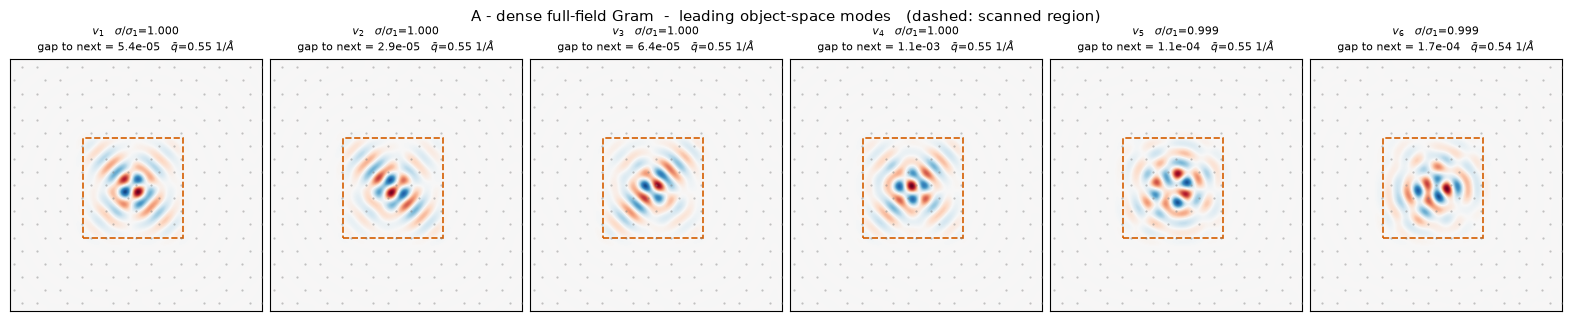

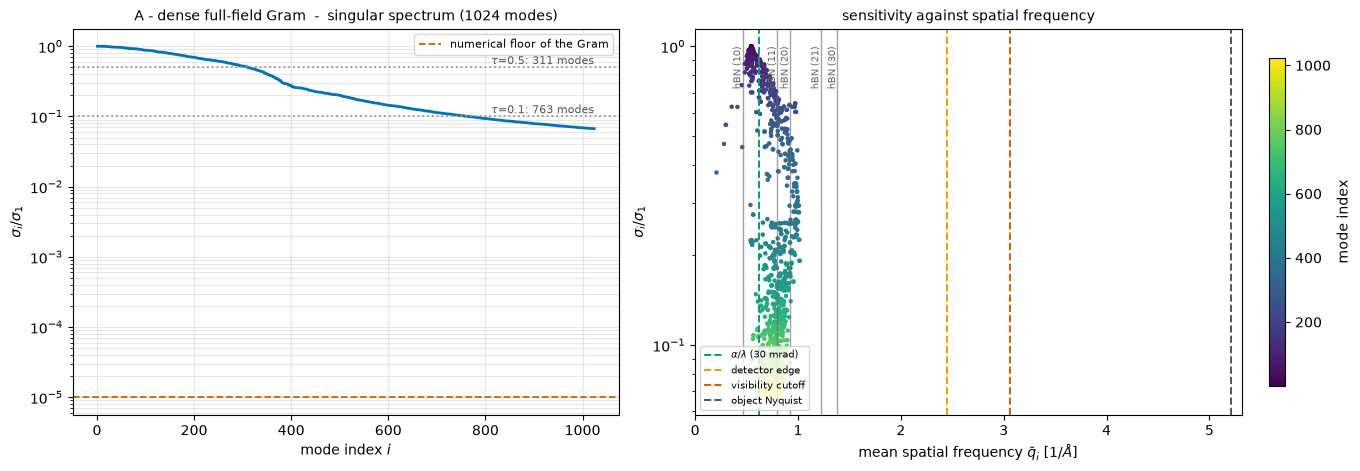

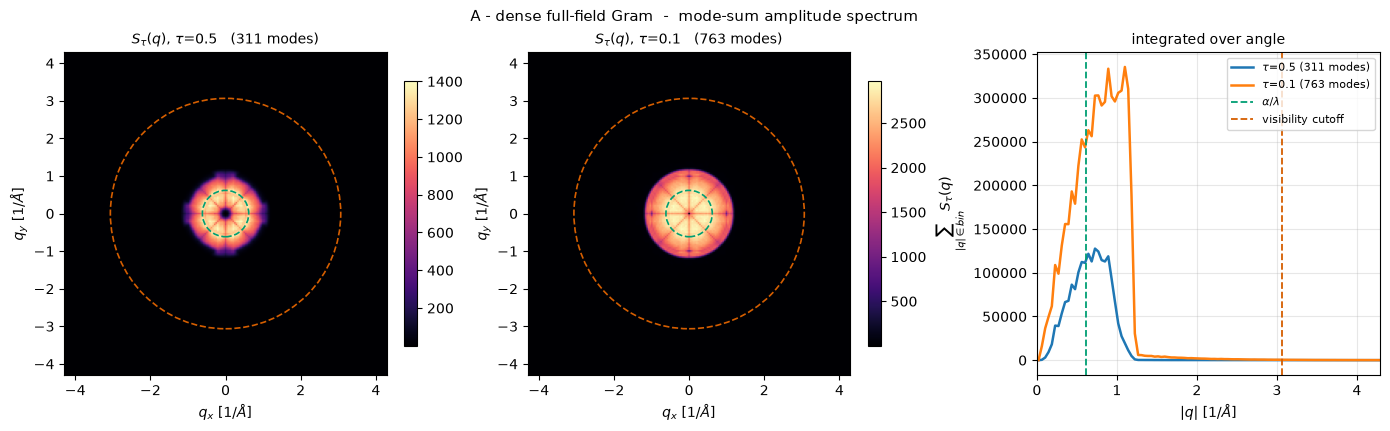

In [10]:
results["A"] = finish_result(
    name="A - dense full-field Gram", sigma=dense_sigma, modes=dense_modes,
    origin=(0, 0), extent=object_extent_ang, n_domain=n_object_pixels,
    complete=False, show_scan_box=True,
    seconds=dense_build_seconds + dense_solve_seconds,
    numerical_floor=1e-5,
    notes=f"float32, {DENSE_N_MODES} of {n_object_pixels:,} modes",
)
print("modes within a relative distance of sigma_1:", results["A"]["degeneracy"])
report_method(results["A"])

---

# B. The windowed Gram

The dense route above pays $2N^2D$ flops per position and 15.9 GB of device memory because
$N$ is every pixel of the object. Most of those pixels are not the ones in question: an
excitation is localized, and the quantity of interest is which perturbations *of a
particular region* the scan can see. Restricting the Gram to a window of object pixels
attacks both costs at once, and it changes the problem in ways that have to be stated.

**The window must lie strictly inside the scanned region.** The scan positions are where
probe *centres* go, and illumination extends about a probe radius beyond them. A window
placed at the edge of the scan would be covered unevenly - some of its pixels seen by many
positions, others by few - and $A^{\mathsf T}A$ carries that weighting directly into its
leading modes, which would then report the scan bookkeeping rather than the optics. Inside
the scanned region the coverage is flat to within the scan-step ripple. The cell below
asserts the containment and prints the coverage uniformity actually achieved inside the
window.

**How it is built.** The restriction makes the structured accumulation worthwhile. Writing
$A[k,p] = -2\,\mathrm{Im}(\Psi_k^{*}F[k,p]\psi_p)$ and using
$\mathrm{Im}(a)\mathrm{Im}(b) = \tfrac12[\mathrm{Re}(a\bar b) - \mathrm{Re}(ab)]$, the sum
over detector pixels collapses in closed form,

$$G[p,q] = \sum_k A[k,p]A[k,q]
= 2\,\mathrm{Re}\!\left[\psi_p\bar\psi_q\,T_1(p-q)\right] - 2\,\mathrm{Re}\!\left[\psi_p\psi_q\,T_2(p+q)\right],$$

because $F[k,p]\overline{F[k,q]}$ depends only on $p-q$ and $F[k,p]F[k,q]$ only on $p+q$.
The two lookup tables are single transforms of detector-plane quantities, zero-padded back
onto the object grid,

$$T_1 = \mathcal F\{\mathrm{zeropad}(|\Psi|^2)\}, \qquad
T_2 = \mathcal F\{\mathrm{zeropad}(\bar\Psi^{\,2})\},$$

so one position costs two FFTs and two outer products - about $4N^2$ flops instead of
$2N^2D$. This is an identity, not an approximation; it is also *more* accurate than the
GEMM at equal precision, because the sum over the $D$ detector pixels is performed by the
FFT rather than by accumulating $D$ rounded products.

**How it is diagonalized, and what that buys.** The dimensionality falls from $N = 63\,001$
to $W^2$ - here $96^2 = 9\,216$ - and at that size the Gram is 0.68 GB in float64 and a
complete `eigh` costs about a second. So this is the only one of the three methods that
returns the **entire** spectrum: not just the well-measured end but the roll-off and the
blind end, which is what fixes where the visibility cutoff actually bites. It is also the
only one that can afford float64, pushing the Gram's own floor from $10^{-5}\sigma_1$ down
to $10^{-8}\sigma_1$.

**Does it change the degeneracy?** It should, and the reason is geometric. Over a field
many times the probe width the operator is nearly translation-invariant, so a perturbation
at the most-visible spatial frequency is equally visible wherever it sits; the top of the
full-field spectrum is correspondingly degenerate, because translating a mode produces
another mode with nearly the same singular value. How many independent translates fit is
set by the available *area*, so confining the support to a window should cut the cluster
sizes substantially. The window does not remove degeneracy altogether - a square window
still has the symmetry of a square, which forces two- and four-fold degeneracies of its own
- but the clusters should be smaller than at full field.

Whether near-degeneracy actually makes the vectors unusable is a separate question from how
close the singular values are, and it is settled by re-running the same iteration from a
different random seed: if the two runs return the same vectors, the gaps are small but
resolved and the pictures can be read individually. Section A reports that test.

The area ratio is printed below alongside the measured cluster sizes as a crude reference
rather than as a prediction to be met. It is only a counting argument, and it breaks down
in both directions: a window narrower than a few periods of the mode in question stops
admitting independent translates at all, while the window's own symmetry adds degeneracies
that have nothing to do with translation. The measured counts are the result; the ratio is
there to show which effect dominates.

**What is discarded.** This is the part that must not be glossed. Restricting the Gram to a
window is exactly taking a principal submatrix of the full-field Gram - the same object
pixel basis, a subset of the indices - and Cauchy's interlacing theorem then bounds every
eigenvalue of the restriction by the corresponding eigenvalue of the whole,

$$\lambda_i(G_{\mathrm{window}}) \le \lambda_i(G_{\mathrm{full}}).$$

So the window can only understate sensitivity, never overstate it. What it discards is any
perturbation with support crossing the window edge: the restriction implicitly asserts that
the phase perturbation is exactly zero outside, so a mode of the full problem that extends
past the boundary is not approximated by this calculation, it is excluded from it. The
window is therefore the right tool for asking about a localized excitation and the wrong one
for asking about an extended one, and the final section measures how far apart the two
answers fall here.

In [11]:
window_real_dtype, window_complex_dtype = fsg.dtypes_for(WINDOW_PRECISION)
window_rows, window_cols = fsg.window_indices(n_object_y, n_object_x, GRAM_WINDOW_WIDTH_PX)
window_origin = (int(window_rows[0]), int(window_cols[0]))
n_window_pixels = len(window_rows) * len(window_cols)
window_extent_ang = [float(object_x_ang[window_cols[0]]), float(object_x_ang[window_cols[-1]]),
                     float(object_y_ang[window_rows[0]]), float(object_y_ang[window_rows[-1]])]

# The containment the section text requires, asserted rather than assumed.  The largest
# admissible width is computed rather than guessed: a centred window grows in steps of two
# pixels and the scan box is not centred on the grid to within a pixel, so the bound is not
# something to round by eye.
def window_fits(width):
    row0, col0 = (n_object_y - width) // 2, (n_object_x - width) // 2
    return (object_x_ang[col0] >= scan_box_ang[0]
            and object_x_ang[col0 + width - 1] <= scan_box_ang[1]
            and object_y_ang[row0] >= scan_box_ang[2]
            and object_y_ang[row0 + width - 1] <= scan_box_ang[3])


largest_admissible_width = max(w for w in range(8, min(n_object_y, n_object_x) + 1)
                               if window_fits(w))
inside = window_fits(GRAM_WINDOW_WIDTH_PX)
window_coverage = coverage[np.ix_(window_rows, window_cols)]

print(f"window                     : {GRAM_WINDOW_WIDTH_PX}x{GRAM_WINDOW_WIDTH_PX} object px "
      f"= {GRAM_WINDOW_WIDTH_PX * object_sampling_ang[0]:.2f} x "
      f"{GRAM_WINDOW_WIDTH_PX * object_sampling_ang[1]:.2f} A")
print(f"window extent [A]          : x {window_extent_ang[0]:.2f}-{window_extent_ang[1]:.2f},"
      f"  y {window_extent_ang[2]:.2f}-{window_extent_ang[3]:.2f}")
print(f"scanned region [A]         : x {scan_box_ang[0]:.2f}-{scan_box_ang[1]:.2f},"
      f"  y {scan_box_ang[2]:.2f}-{scan_box_ang[3]:.2f}")
print(f"window inside the scan     : {inside}")
print(f"largest admissible width   : {largest_admissible_width} px "
      f"({largest_admissible_width * object_sampling_ang[0]:.2f} A)")
assert inside, (f"the window must lie strictly inside the scanned region; "
                f"the largest centred width that fits is {largest_admissible_width} px")
print(f"coverage inside the window : max/min = {window_coverage.max() / window_coverage.min():.3f}"
      f"   (1.000 would be perfectly uniform illumination)")
print(f"dimensionality             : {n_object_pixels:,} -> {n_window_pixels:,} "
      f"({n_window_pixels / n_object_pixels:.1%} of the full problem)")
print(f"Gram                       : {n_window_pixels:,}^2 "
      f"({(8 if WINDOW_PRECISION == 'float64' else 4) * n_window_pixels ** 2 / 1e9:.2f} GB)")
print(f"flops/position             : {4 * n_window_pixels ** 2:.2e} structured  vs  "
      f"{2 * n_window_pixels ** 2 * n_detector_pixels:.2e} as a matrix product "
      f"({n_detector_pixels / 2:.0f}x)\n")

torch.cuda.empty_cache()
start_time = time.time()
window_gram = fsg.structured_gram_accumulate(
    exit_wave_by_scan, camera_wave_by_scan, window_rows, window_cols,
    window_real_dtype, window_complex_dtype,
    row_block=GRAM_ROW_BLOCK, symmetric=GRAM_SYMMETRIC,
    progress_every=max(1, n_scan_positions // 4),
)
torch.cuda.synchronize()
window_build_seconds = time.time() - start_time
print(f"\nstructured Gram accumulated in {window_build_seconds:.1f} s")

start_time = time.time()
eigenvalues, eigenvectors = torch.linalg.eigh(window_gram)
window_sigma = eigenvalues.flip(0).clamp(min=0).sqrt()
window_modes = eigenvectors.flip(1).T.reshape(
    n_window_pixels, GRAM_WINDOW_WIDTH_PX, GRAM_WINDOW_WIDTH_PX
)
flat = window_modes.reshape(n_window_pixels, -1)
peak_sign = torch.sign(flat.gather(1, flat.abs().argmax(1, keepdim=True)))
window_modes = (window_modes * peak_sign[:, None]).to(torch.float32).cpu().numpy()
window_sigma = window_sigma.cpu().numpy()
torch.cuda.synchronize()
window_solve_seconds = time.time() - start_time
del window_gram, eigenvalues, eigenvectors, flat
torch.cuda.empty_cache()

window_floor = 1e-8 if WINDOW_PRECISION == "float64" else 1e-5
n_above_floor = int((window_sigma > window_floor * window_sigma[0]).sum())
print(f"complete eigh of {n_window_pixels:,}^2 in {window_solve_seconds:.1f} s")
print(f"sigma_1                    : {window_sigma[0]:.6e}")
print(f"modes above the {window_floor:.0e} floor : {n_above_floor} / {n_window_pixels} "
      f"({n_above_floor / n_window_pixels:.1%})")

window                     : 94x94 object px = 9.02 x 9.02 A
window extent [A]          : x 7.49-16.42,  y 7.49-16.42
scanned region [A]         : x 7.00-16.50,  y 7.00-16.50
window inside the scan     : True
largest admissible width   : 94 px (9.02 A)
coverage inside the window : max/min = 1.407   (1.000 would be perfectly uniform illumination)
dimensionality             : 63,001 -> 8,836 (14.0% of the full problem)
Gram                       : 8,836^2 (0.62 GB)
flops/position             : 3.12e+08 structured  vs  2.21e+12 as a matrix product (7080x)



      100/400 positions (   1.0 s)


      200/400 positions (   1.9 s)


      300/400 positions (   2.8 s)


      400/400 positions (   3.7 s)



structured Gram accumulated in 3.8 s


complete eigh of 8,836^2 in 2.7 s
sigma_1                    : 6.504958e-03
modes above the 1e-08 floor : 8190 / 8836 (92.7%)


modes within a relative distance of sigma_1:
   full field (A): {0.001: 4, 0.01: 23, 0.05: 54, 0.1: 88}
   window     (B): {0.001: 4, 0.01: 21, 0.05: 50, 0.1: 79}

area ratio window/full = 0.1403   (a counting reference, not a prediction -- see the section text)


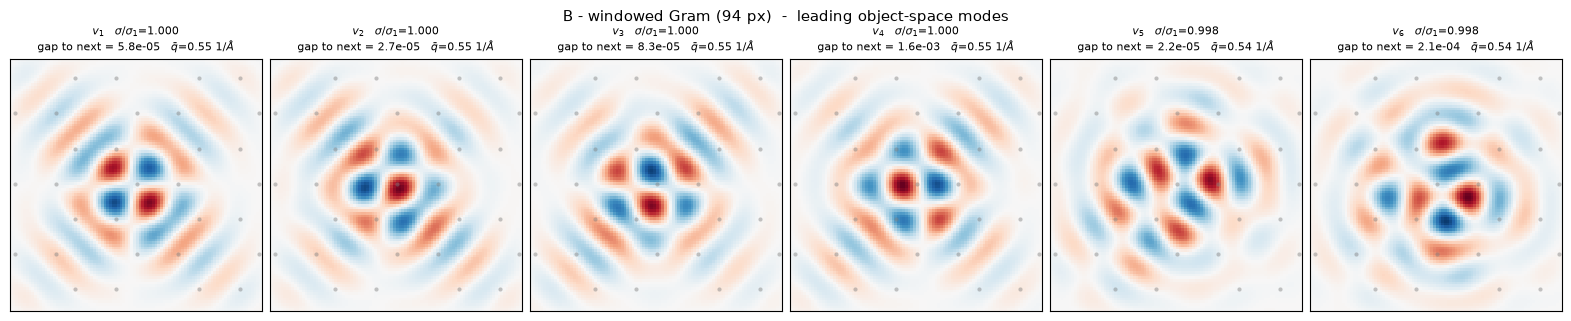

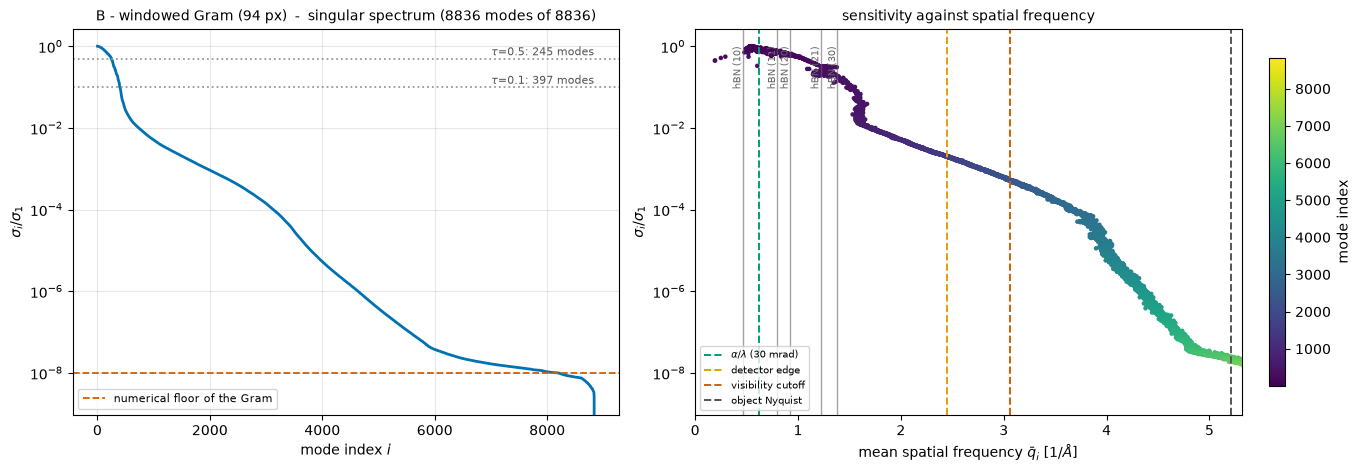

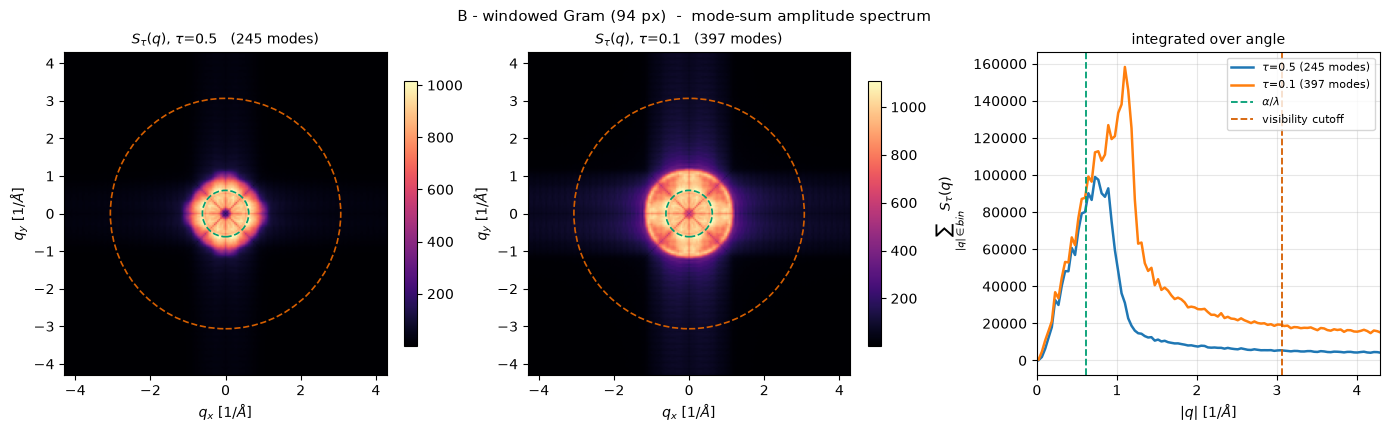

In [12]:
results["B"] = finish_result(
    name=f"B - windowed Gram ({GRAM_WINDOW_WIDTH_PX} px)", sigma=window_sigma,
    modes=window_modes, origin=window_origin, extent=window_extent_ang,
    n_domain=n_window_pixels, complete=True, show_scan_box=False,
    seconds=window_build_seconds + window_solve_seconds,
    numerical_floor=window_floor,
    notes=f"{WINDOW_PRECISION}, complete spectrum",
)
print("modes within a relative distance of sigma_1:")
print("   full field (A):", results["A"]["degeneracy"])
print("   window     (B):", results["B"]["degeneracy"])
print(f"\narea ratio window/full = {n_window_pixels / n_object_pixels:.4f}"
      "   (a counting reference, not a prediction -- see the section text)")
report_method(results["B"])

---

# C. The fast full-field route: never form the Gram

Sections A and B both build $A^{\mathsf T}A$ and then diagonalize it. The Gram is what makes
the problem tractable, and it is also the one avoidable source of error in it: squaring the
operator squares the condition number, so half the available digits are spent before the
eigensolver starts. Section A had to accept a $10^{-5}\sigma_1$ floor because a float64
Gram on the full grid does not fit in memory. This section keeps the full field and drops
the Gram entirely.

**The new way the diagonalization is done.** Subspace iteration needs only the *action* of
the operator, never its entries. Both actions are available in closed form as FFTs on the
object grid:

$$A_{\mathbf R}h = -2\,\mathrm{Im}\!\left[\overline{\Psi_{0,\mathbf R}}\,
\mathrm{crop}\,\mathcal F\{\psi_{0,\mathbf R}h\}\right], \qquad
A_{\mathbf R}^{\mathsf T}g = 2\,\mathrm{Re}\!\left[\psi_{0,\mathbf R}\,
\mathcal F\{\mathrm{zeropad}(j\,g\,\overline{\Psi_{0,\mathbf R}})\}\right],$$

the second following from the first because the centred DFT matrix is symmetric and
zero-padding is the adjoint of the crop.

Here $Q$ is the **sketch basis**: an $N \times (k+p)$ matrix, $63\,001 \times 1280$ in this
configuration, whose columns are orthonormal real phase perturbations over the object grid
($k$ modes to keep, $p$ extra carried as oversampling; it is the variable `basis` in the
code below). It starts as random Gaussian vectors. Iterating

$$Q \leftarrow \mathrm{qr}\left(\sum_{\mathbf R} A_{\mathbf R}^{\mathsf T}(A_{\mathbf R}Q)\right)$$

drives it onto the leading right-singular subspace of $A$: applying $A^{\mathsf T}A$ stretches
each column towards the directions with the largest $\sigma$, and the QR re-orthonormalizes
so that the columns do not all collapse onto $v_1$ - the $Q$ above is exactly the orthonormal
factor of that decomposition, with $R$ discarded. $Q$ is not the modes; it is a basis for a
subspace that contains them, and the Rayleigh-Ritz step below is what separates them out.
The oversampling $p$ is there because the subspace converges faster than any individual
vector in it, so the $k$ modes that are kept sit inside a converged subspace rather than at
its ragged edge.

No matrix larger than $N \times (k+p)$ ever exists - 0.3 GB here against 15.9 GB for the
Gram. The inner detector-space response is consumed by the adjoint inside the same scan
chunk and never accumulated across positions, which is what keeps the memory flat in $M$.

**Does it change the eigenvalues, and do they make more sense?** Both, and in opposite
directions.

*Better:* the Ritz step is taken on the small projected matrix rather than on the big one.
Accumulating $T = \sum_{\mathbf R}(A_{\mathbf R}Q)^{\mathsf T}(A_{\mathbf R}Q)
= Q^{\mathsf T}A^{\mathsf T}AQ$ gives a $(k+p)\times(k+p)$ matrix whose eigenvalues are
$\sigma^2$ of $A$ restricted to $\mathrm{span}(Q)$, and whose eigenvectors rotate $Q$ into
the modes themselves, $v_i = (QV)_i$. The condition number that gets squared is therefore the one *of the
retained subspace*, around $\sigma_1/\sigma_k \approx 10$ here, rather than that of the full
operator, which spans eight decades or more. The float32 floor of section A simply does not
arise; these singular values are limited by the convergence of the iteration and not by the
arithmetic.

*Worse:* only the leading $k$ are available at all, and a Rayleigh-Ritz value computed from
a subspace is a lower bound - $\hat\sigma_i \le \sigma_i$, with equality only at convergence.
The gap that governs convergence is $\sigma_{k+p}/\sigma_k$, and at full field the spectrum
is dense near the top, so the trailing modes of the retained block converge slowly and are
the ones to distrust. The drift of the Ritz values over the last iteration is printed for
exactly this reason.

So this method gives the same modes as section A, from the same full field, with better
conditioning and a fiftieth of the memory - but it cannot see the blind end of the spectrum
at all, which is what section B is for. The three are complementary rather than redundant.

In [13]:
free_exit_wave = exit_wave_by_scan.to(torch.complex64)
free_camera_wave = camera_wave_by_scan.to(torch.complex64)


def gram_action(basis, chunk=FREE_SCAN_CHUNK, want_projection=False):
    '''sum_R A_R^T (A_R Q), and optionally sum_R (A_R Q)^T (A_R Q).

    The detector-space response of a scan chunk is consumed by the adjoint before the next
    chunk is read, so peak memory is set by ``chunk`` and never by the number of positions.
    '''
    out = torch.zeros_like(basis)
    projection = (torch.zeros(len(basis), len(basis), device=basis.device, dtype=torch.float32)
                  if want_projection else None)
    for start in range(0, n_scan_positions, chunk):
        span = slice(start, min(start + chunk, n_scan_positions))
        response = -2.0 * (
            torch.conj(free_camera_wave[span])[:, None]
            * crop_to_detector(centered_dft_torch(free_exit_wave[span][:, None] * basis[None]))
        ).imag
        if want_projection:
            projection += torch.einsum("mkij,mlij->kl", response, response)
        weighted = 1j * response.to(torch.complex64) * torch.conj(free_camera_wave[span])[:, None]
        padded = torch.zeros(weighted.shape[0], len(basis), n_object_y, n_object_x,
                             device=basis.device, dtype=torch.complex64)
        padded[..., detector_row_start:detector_row_start + n_detector_y,
               detector_col_start:detector_col_start + n_detector_x] = weighted
        out += (2.0 * (free_exit_wave[span][:, None] * centered_dft_torch(padded)).real).sum(0)
        del response, weighted, padded
    return (out, projection) if want_projection else out


def matrix_free_top_k(n_modes, n_oversample, n_iterations, seed):
    sketch = n_modes + n_oversample
    generator = torch.Generator(device=TORCH_DEVICE).manual_seed(seed)
    basis = torch.randn(sketch, n_object_y, n_object_x, device=TORCH_DEVICE,
                        dtype=torch.float32, generator=generator)
    basis = torch.linalg.qr(basis.reshape(sketch, -1).T)[0].T.reshape(sketch, n_object_y, n_object_x)

    def ritz(basis):
        _, projection = gram_action(basis, want_projection=True)
        projection = 0.5 * (projection + projection.T)
        return torch.linalg.eigh(projection)

    previous = None
    for iteration in range(n_iterations):
        applied = gram_action(basis).reshape(sketch, -1).T
        basis = torch.linalg.qr(applied)[0].T.reshape(sketch, n_object_y, n_object_x)
        if iteration == n_iterations - 2:
            previous = ritz(basis)[0].flip(0)[:n_modes].clamp(min=0).sqrt()
        print(f"  iteration {iteration + 1:3d}/{n_iterations}", end="\r", flush=True)

    values, vectors = ritz(basis)
    sigma = values.flip(0)[:n_modes].clamp(min=0).sqrt()
    modes = (vectors.flip(1)[:, :n_modes].T @ basis.reshape(sketch, -1)
             ).reshape(n_modes, n_object_y, n_object_x)
    drift = float(((sigma - previous).abs() / sigma[0]).max()) if previous is not None else np.nan
    return sigma, modes, drift


torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
start_time = time.time()
free_sigma, free_modes, free_drift = matrix_free_top_k(
    FREE_N_MODES, FREE_N_OVERSAMPLE, FREE_N_ITERATIONS, RANDOM_SEED
)
torch.cuda.synchronize()
free_seconds = time.time() - start_time

flat = free_modes.reshape(FREE_N_MODES, -1)
peak_sign = torch.sign(flat.gather(1, flat.abs().argmax(1, keepdim=True)))
free_modes = (free_modes * peak_sign[:, None]).cpu().numpy()
free_sigma = free_sigma.cpu().numpy()
del flat, free_exit_wave, free_camera_wave
torch.cuda.empty_cache()

print(f"\nmatrix-free top-{FREE_N_MODES} in {free_seconds:.1f} s "
      f"({FREE_N_ITERATIONS} iterations, {FREE_N_OVERSAMPLE} oversampled)")
print(f"peak device memory                 : {torch.cuda.max_memory_allocated() / 1e9:.2f} GB"
      f"   (the Gram alone would be {4 * n_object_pixels ** 2 / 1e9:.1f} GB)")
print(f"Ritz drift over the last iteration : {free_drift:.2e} x sigma_1")
print(f"sigma_1                            : {free_sigma[0]:.6e}")
print(f"sigma_{FREE_N_MODES}/sigma_1       : {free_sigma[-1] / free_sigma[0]:.4f}")


matrix-free top-1024 in 143.2 s (20 iterations, 256 oversampled)
peak device memory                 : 7.86 GB   (the Gram alone would be 15.9 GB)
Ritz drift over the last iteration : 3.55e-06 x sigma_1
sigma_1                            : 6.510889e-03
sigma_1024/sigma_1       : 0.0669


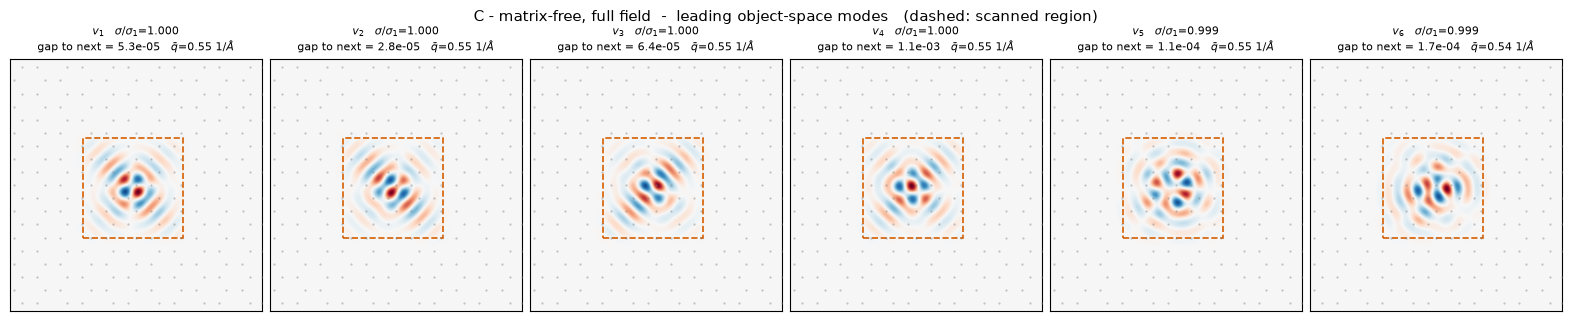

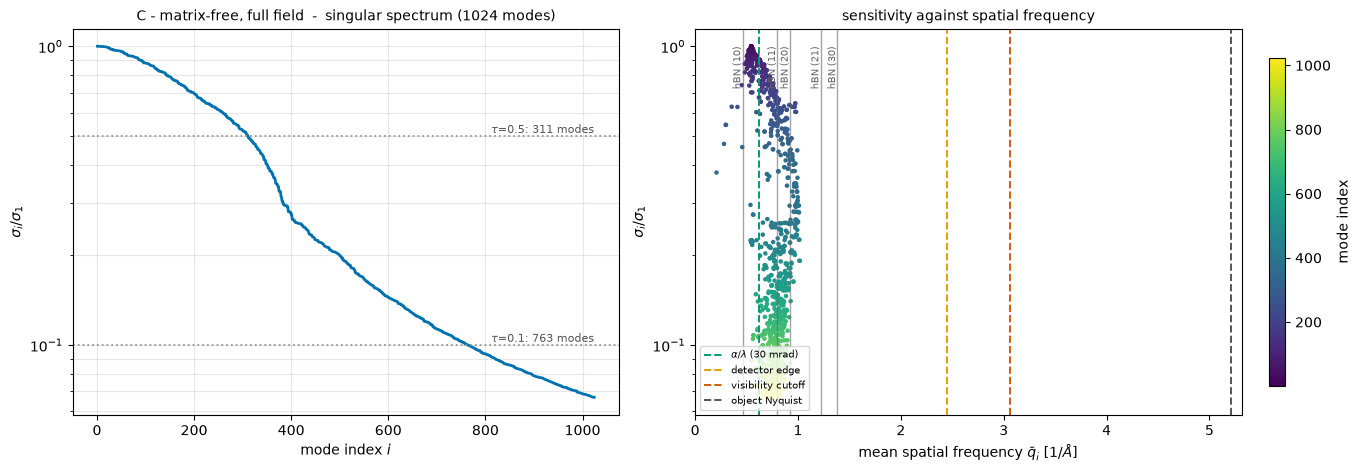

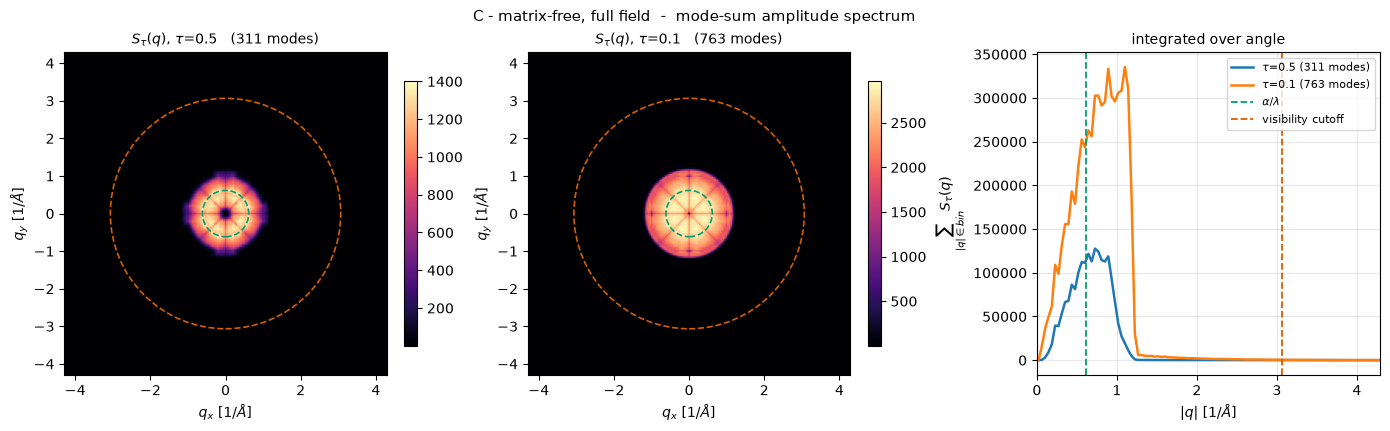

In [14]:
results["C"] = finish_result(
    name="C - matrix-free, full field", sigma=free_sigma, modes=free_modes,
    origin=(0, 0), extent=object_extent_ang, n_domain=n_object_pixels,
    complete=False, show_scan_box=True, seconds=free_seconds,
    numerical_floor=None,
    notes=f"no Gram, {FREE_N_MODES} of {n_object_pixels:,} modes",
)
report_method(results["C"])

---

# Comparing the three

## The two bounds, checked

Section A is the baseline. Both alternatives should sit below it, for the two reasons given
at the top: the window Gram is a principal submatrix of the full-field Gram, so Cauchy
interlacing applies; and matrix-free subspace iteration returns Rayleigh-Ritz values, which
underestimate until convergence. A violation of either bound by more than the numerical
floor would mean one of the three operators is not the operator it claims to be.

One caveat on what the check can prove. The baseline is itself obtained by subspace
iteration, so its own $\sigma_i$ are lower bounds too, and they are loosest exactly where
the iteration has converged least - at the trailing end of the retained block. A small
excess of $B$ or $C$ over $A$ there is evidence that $A$ has not converged, not that the
bound has failed. The Ritz drifts printed in each section say which end to trust; the
bounds are informative where the drift is small compared with the ratios plotted.

sigma_1   A (dense full field)  : 6.510881e-03
          B (window)            : 6.504958e-03   (0.9991 x A)
          C (matrix-free)       : 6.510889e-03   (1.0000 x A)

C/A over the first 1024 modes   : min 1.0000, median 1.0000, max 1.0000
B/A over the first 1024 modes   : min 0.0716, median 0.1313, max 0.9991

Cauchy interlacing  lambda_i(B) <= lambda_i(A) : HOLDS   (largest B/A = 0.999090)
Ritz bound          sigma_i(C) <= sigma_i(A)   : HOLDS   (largest C/A = 1.000048)


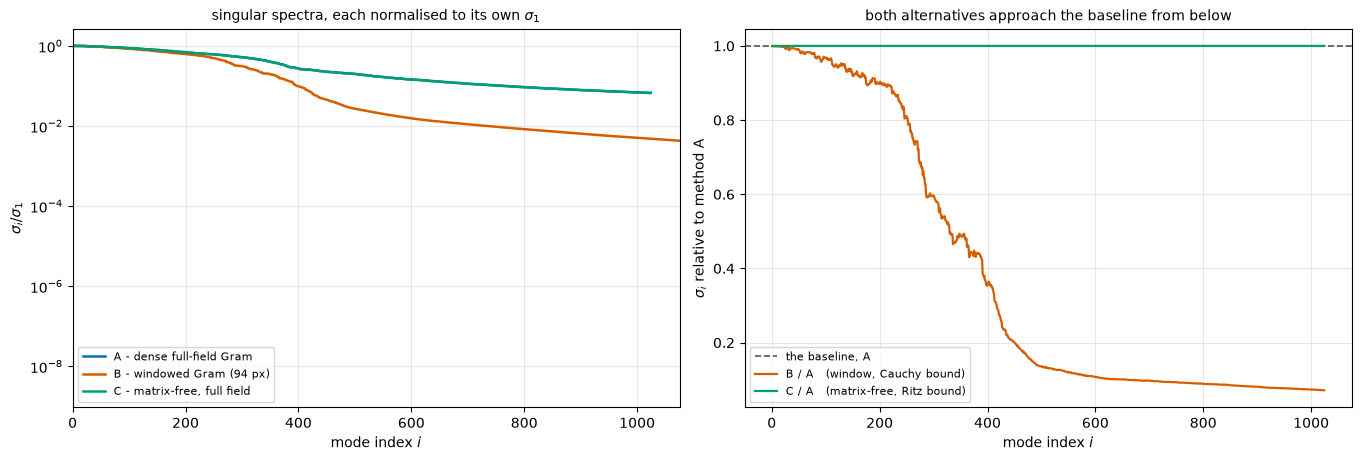

In [15]:
n_compare = min(len(results["A"]["sigma"]), len(results["C"]["sigma"]))
sigma_a = results["A"]["sigma"][:n_compare]
sigma_c = results["C"]["sigma"][:n_compare]
n_compare_b = min(n_compare, len(results["B"]["sigma"]))
sigma_b = results["B"]["sigma"][:n_compare_b]

ratio_c = sigma_c / sigma_a
ratio_b = sigma_b / sigma_a[:n_compare_b]

print(f"sigma_1   A (dense full field)  : {sigma_a[0]:.6e}")
print(f"          B (window)            : {results['B']['sigma'][0]:.6e}"
      f"   ({results['B']['sigma'][0] / sigma_a[0]:.4f} x A)")
print(f"          C (matrix-free)       : {sigma_c[0]:.6e}"
      f"   ({sigma_c[0] / sigma_a[0]:.4f} x A)")
print()
print(f"C/A over the first {n_compare} modes   : min {ratio_c.min():.4f}, "
      f"median {np.median(ratio_c):.4f}, max {ratio_c.max():.4f}")
print(f"B/A over the first {n_compare_b} modes   : min {ratio_b.min():.4f}, "
      f"median {np.median(ratio_b):.4f}, max {ratio_b.max():.4f}")
print()
tolerance = 1e-4
print(f"Cauchy interlacing  lambda_i(B) <= lambda_i(A) : "
      f"{'HOLDS' if ratio_b.max() <= 1.0 + tolerance else 'VIOLATED'}"
      f"   (largest B/A = {ratio_b.max():.6f})")
print(f"Ritz bound          sigma_i(C) <= sigma_i(A)   : "
      f"{'HOLDS' if ratio_c.max() <= 1.0 + tolerance else 'VIOLATED'}"
      f"   (largest C/A = {ratio_c.max():.6f})")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5), constrained_layout=True)
index_a = np.arange(1, len(results["A"]["sigma"]) + 1)
index_b = np.arange(1, len(results["B"]["sigma"]) + 1)
index_c = np.arange(1, len(results["C"]["sigma"]) + 1)
for index, result, colour in [(index_a, results["A"], "#0072B2"),
                              (index_b, results["B"], "#D55E00"),
                              (index_c, results["C"], "#009E73")]:
    axes[0].semilogy(index, result["sigma"] / result["sigma"][0], color=colour,
                     linewidth=1.8, label=result["name"])
axes[0].set_xlabel("mode index $i$"); axes[0].set_ylabel("$\\sigma_i/\\sigma_1$")
axes[0].set_xlim(0, max(len(sigma_a), n_compare_b) * 1.05)
axes[0].set_title("singular spectra, each normalised to its own $\\sigma_1$", fontsize=10)
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3, which="both")

axes[1].axhline(1.0, color="#555555", linewidth=1.2, linestyle="--", label="the baseline, A")
axes[1].plot(np.arange(1, n_compare_b + 1), ratio_b, color="#D55E00", linewidth=1.6,
             label="B / A   (window, Cauchy bound)")
axes[1].plot(np.arange(1, n_compare + 1), ratio_c, color="#009E73", linewidth=1.6,
             label="C / A   (matrix-free, Ritz bound)")
axes[1].set_xlabel("mode index $i$"); axes[1].set_ylabel("$\\sigma_i$ relative to method A")
axes[1].set_title("both alternatives approach the baseline from below", fontsize=10)
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
plt.show()

## Degeneracy, and how much a single mode picture is worth

The top of a full-field spectrum is expected to be crowded, because the operator is nearly
translation-invariant over the illuminated area: a perturbation at the best-measured
frequency is about as visible wherever it sits and at whatever orientation, so translating
a mode produces another mode with nearly the same singular value.

Crowded is not the same as degenerate, and the difference decides whether a mode picture
means anything. If a cluster of singular values is *exactly* equal, every orthogonal basis
of the cluster is an equally valid set of eigenvectors and the ones returned are set by the
random seed alone. If the values are merely close, the eigenvectors are still uniquely
determined, and a converged iteration will find the same ones every time.

The gaps alone cannot distinguish these cases, so section A runs the same iteration from a
second, independent seed and compares the two sets of vectors mode by mode. That overlap is
the direct measurement; the cluster-size table beside it gives the context.

                                    within 0.1%       1%       5%      10%   of sigma_1
A - dense full-field Gram                     4       23       54       88
B - windowed Gram (94 px)                     4       21       50       79
C - matrix-free, full field                   4       23       54       88

window / full-field area ratio : 0.1403
cluster size at full field, scaled by that ratio, against the window's own:
   within 1% of sigma_1 :   23 x 0.1403 =    3.2   vs   21 measured in the window
   within 5% of sigma_1 :   54 x 0.1403 =    7.6   vs   50 measured in the window
   within 10% of sigma_1 :   88 x 0.1403 =   12.3   vs   79 measured in the window


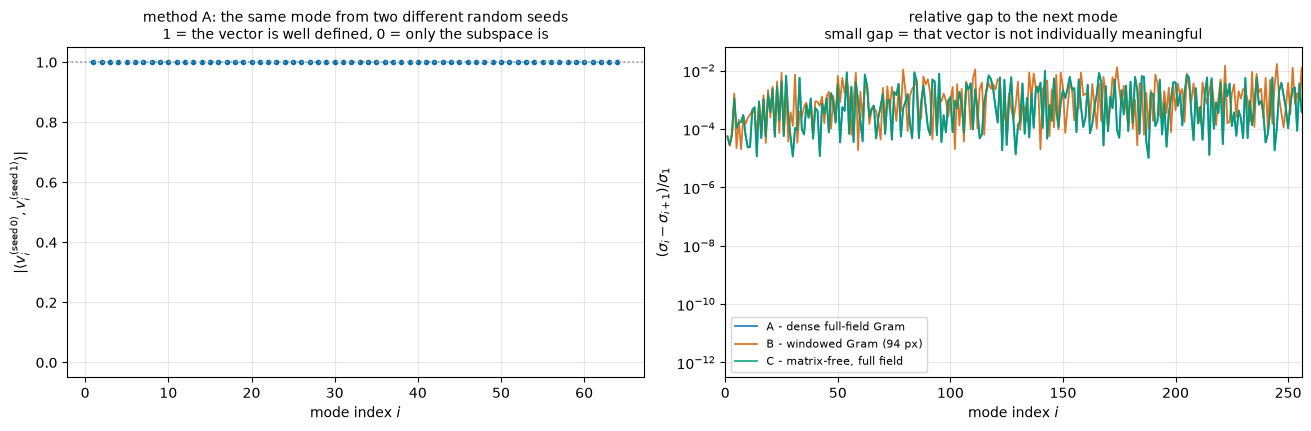

In [16]:
print(f"{'':34s} {'within 0.1%':>12s} {'1%':>8s} {'5%':>8s} {'10%':>8s}   of sigma_1")
for key in ("A", "B", "C"):
    counts = results[key]["degeneracy"]
    print(f"{results[key]['name']:34s} {counts[0.001]:12d} {counts[0.01]:8d} "
          f"{counts[0.05]:8d} {counts[0.1]:8d}")
area_ratio = n_window_pixels / n_object_pixels
print(f"\nwindow / full-field area ratio : {area_ratio:.4f}")
print("cluster size at full field, scaled by that ratio, against the window's own:")
for tol in (0.01, 0.05, 0.1):
    print(f"   within {tol:.0%} of sigma_1 : {results['A']['degeneracy'][tol]:4d} x "
          f"{area_ratio:.4f} = {results['A']['degeneracy'][tol] * area_ratio:6.1f}"
          f"   vs {results['B']['degeneracy'][tol]:4d} measured in the window")

fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.2), constrained_layout=True)
axes[0].plot(np.arange(1, len(seed_overlap) + 1), seed_overlap, ".", color="#0072B2")
axes[0].set_xlabel("mode index $i$")
axes[0].set_ylabel("$|\\langle v_i^{(\\mathrm{seed}\\,0)}, v_i^{(\\mathrm{seed}\\,1)}\\rangle|$")
axes[0].set_ylim(-0.05, 1.05)
axes[0].axhline(1.0, color="#999999", linestyle=":", linewidth=1.2)
axes[0].set_title("method A: the same mode from two different random seeds\n"
                  "1 = the vector is well defined, 0 = only the subspace is", fontsize=10)
axes[0].grid(alpha=0.3)

for key, colour in [("A", "#0072B2"), ("B", "#D55E00"), ("C", "#009E73")]:
    gap = relative_gap(results[key]["sigma"])
    axes[1].semilogy(np.arange(1, len(gap)), np.maximum(gap[:-1], 1e-12), linewidth=1.3,
                     color=colour, alpha=0.85, label=results[key]["name"])
axes[1].set_xlim(0, 256)
axes[1].set_xlabel("mode index $i$")
axes[1].set_ylabel("$(\\sigma_i - \\sigma_{i+1})/\\sigma_1$")
axes[1].set_title("relative gap to the next mode\nsmall gap = that vector is not individually meaningful",
                  fontsize=10)
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3, which="both")
plt.show()

## The three mode-sum spectra, side by side

$S_\tau(\mathbf q) = \sum_{i:\sigma_i>\tau\sigma_1}|\hat v_i(\mathbf q)|$ for each method, on
the one frequency grid that the lossless embedding of the window modes makes available. This
is the quantity to compare rather than the individual modes: it is a property of the
well-measured subspace, which all three methods are trying to find, and not of the arbitrary
basis each happens to return for it.

The number of modes entering the sum differs between methods - the window has a smaller
domain, and the two full-field methods are capped at $k$ - so the radial profiles are shown
both raw and normalised to unit area. The raw curves compare *how much* well-measured
subspace each method found; the normalised ones compare *where in frequency* it sits, which
is the part that should agree.

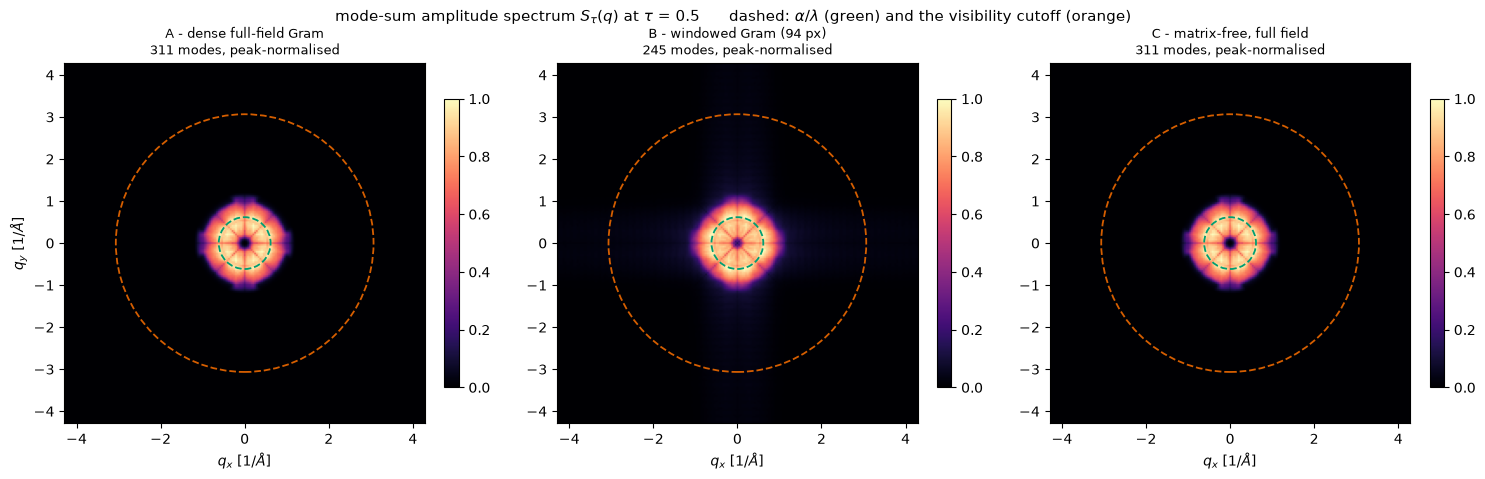

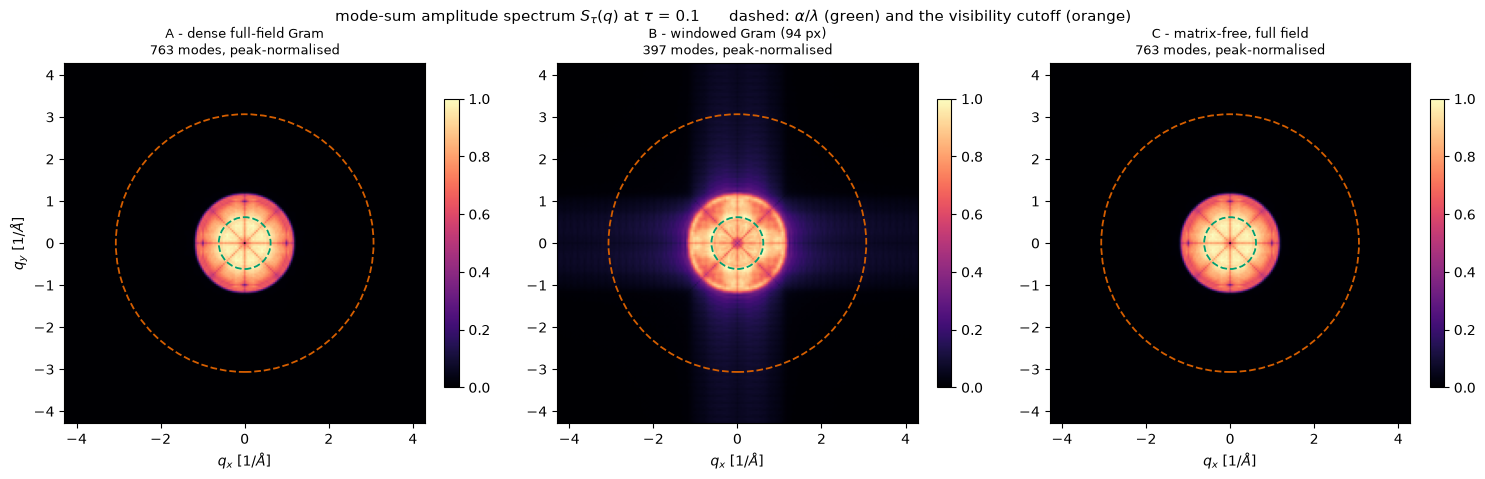

In [17]:
frequency_extent = [frequency_axis_inv_ang[0], frequency_axis_inv_ang[-1],
                    frequency_axis_inv_ang[0], frequency_axis_inv_ang[-1]]
view = visibility_cutoff_inv_ang * 1.4

for tau in SIGMA_THRESHOLDS:
    fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.6), constrained_layout=True)
    for column, key in enumerate(("A", "B", "C")):
        spectrum = results[key]["spectra"][tau]
        ax = axes[column]
        handle = ax.imshow(spectrum / spectrum.max(), extent=frequency_extent, origin="lower",
                           cmap="magma", vmin=0.0, vmax=1.0)
        for frequency, colour in [(aperture_radius_inv_ang, "#009E73"),
                                  (visibility_cutoff_inv_ang, "#D55E00")]:
            ax.add_patch(plt.Circle((0, 0), frequency, fill=False, edgecolor=colour,
                                    linewidth=1.3, linestyle="--"))
        ax.set_xlim(-view, view); ax.set_ylim(-view, view)
        ax.set_xlabel("$q_x$ [1/$\\AA$]")
        if column == 0:
            ax.set_ylabel("$q_y$ [1/$\\AA$]")
        ax.set_title(f"{results[key]['name']}\n{results[key]['counts'][tau]} modes, "
                     f"peak-normalised", fontsize=9)
        fig.colorbar(handle, ax=ax, shrink=0.8)
    fig.suptitle(f"mode-sum amplitude spectrum $S_\\tau(q)$ at $\\tau$ = {tau}"
                 "      dashed: $\\alpha/\\lambda$ (green) and the visibility cutoff (orange)",
                 fontsize=11)
    plt.show()

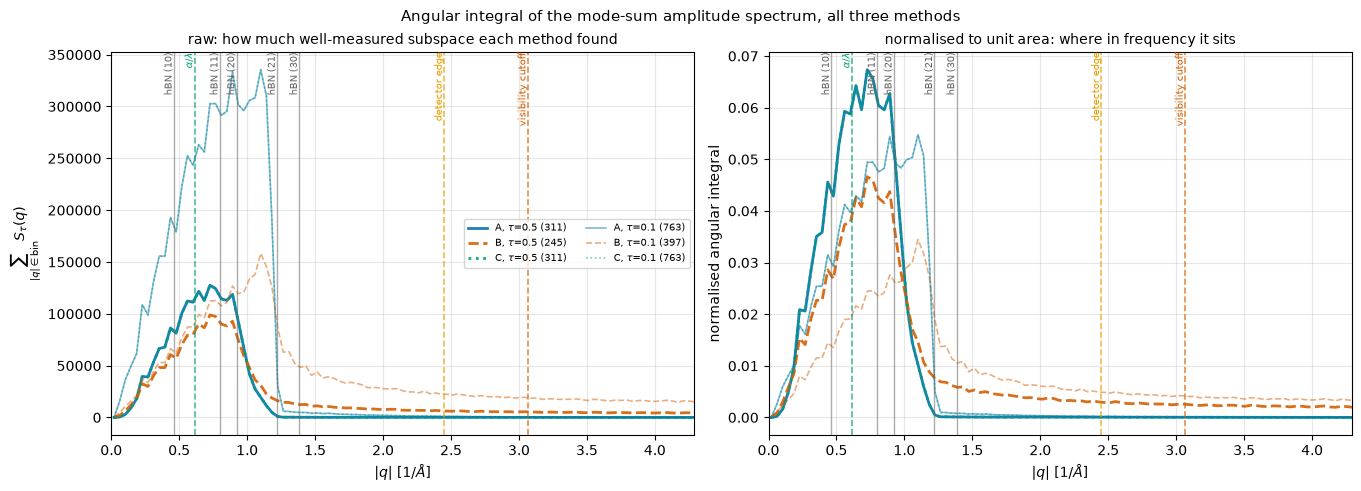

peak of the angular integral [1/A]:
   A - dense full-field Gram          tau=0.5: 0.726  tau=0.1: 1.100
   B - windowed Gram (94 px)          tau=0.5: 0.726  tau=0.1: 1.100
   C - matrix-free, full field        tau=0.5: 0.726  tau=0.1: 1.100

   aperture radius alpha/lambda = 0.617 1/A
   visibility cutoff            = 3.065 1/A

   hBN reflections [1/A]     : (10) 0.461,  (11) 0.799,  (20) 0.922,  (21) 1.220,  (30) 1.383


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), constrained_layout=True)
styles = {"A": ("#0072B2", "-"), "B": ("#D55E00", "--"), "C": ("#009E73", ":")}

for tau, width in zip(SIGMA_THRESHOLDS, (2.0, 1.2)):
    for key in ("A", "B", "C"):
        colour, dash = styles[key]
        profile = results[key]["radial"][tau]
        axes[0].plot(radial_bin_centres_inv_ang, profile, linestyle=dash, color=colour,
                     linewidth=width, alpha=0.9 if tau == SIGMA_THRESHOLDS[0] else 0.5,
                     label=f"{key}, $\\tau$={tau} ({results[key]['counts'][tau]})")
        normalised = profile / max(profile.sum(), 1e-30)
        axes[1].plot(radial_bin_centres_inv_ang, normalised, linestyle=dash, color=colour,
                     linewidth=width, alpha=0.9 if tau == SIGMA_THRESHOLDS[0] else 0.5,
                     label=f"{key}, $\\tau$={tau}")

for ax, title, ylabel in [
    (axes[0], "raw: how much well-measured subspace each method found",
     "$\\sum_{|q|\\in \\mathrm{bin}} S_\\tau(q)$"),
    (axes[1], "normalised to unit area: where in frequency it sits",
     "normalised angular integral"),
]:
    for frequency, colour, label in [
        (aperture_radius_inv_ang, "#009E73", "$\\alpha/\\lambda$"),
        (detector_edge_inv_ang, "#E69F00", "detector edge"),
        (visibility_cutoff_inv_ang, "#D55E00", "visibility cutoff"),
    ]:
        ax.axvline(frequency, color=colour, linestyle="--", linewidth=1.2, alpha=0.7)
        ax.annotate(label, (frequency, ax.get_ylim()[1]), rotation=90, fontsize=7,
                    ha="right", va="top", color=colour)
    # the specimen's own periodicities, solid, so they read as a property of the sample
    for label, frequency in lattice_reflections_inv_ang:
        if frequency > view:
            continue
        ax.axvline(frequency, color="#666666", linestyle="-", linewidth=1.0, alpha=0.55)
        ax.annotate(f"hBN {label}", (frequency, ax.get_ylim()[1]), rotation=90, fontsize=7,
                    ha="right", va="top", color="#666666")
    ax.set_xlim(0, view)
    ax.set_xlabel("$|q|$ [1/$\\AA$]"); ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=10)
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=7, ncol=2)
fig.suptitle("Angular integral of the mode-sum amplitude spectrum, all three methods", fontsize=11)
plt.show()

peak_frequency = {key: {tau: float(radial_bin_centres_inv_ang[np.argmax(results[key]["radial"][tau])])
                        for tau in SIGMA_THRESHOLDS} for key in ("A", "B", "C")}
print("peak of the angular integral [1/A]:")
for key in ("A", "B", "C"):
    print(f"   {results[key]['name']:34s} "
          + "  ".join(f"tau={tau}: {peak_frequency[key][tau]:.3f}" for tau in SIGMA_THRESHOLDS))
print(f"\n   aperture radius alpha/lambda = {aperture_radius_inv_ang:.3f} 1/A")
print(f"   visibility cutoff            = {visibility_cutoff_inv_ang:.3f} 1/A")
print("\n   hBN reflections [1/A]     : "
      + ",  ".join(f"{label} {q:.3f}" for label, q in lattice_reflections_inv_ang))

## Weighting by the singular value: the sensitivity density

Everything above sums the mode transforms with equal weight above a threshold. That
answers *which frequencies the retained subspace occupies*, which is a statement about
the subspace, not about the experiment: the last mode admitted at $\tau=0.1$ responds
ten times more weakly than the first, and the plot does not know it. The weighted
version does, and the quantity to weight by is not a matter of taste - it is fixed by
what $A$ does to a plane wave:

$$D(\mathbf q) = \sum_i \sigma_i^2\,|\hat v_i(\mathbf q)|^2 = \|A f_{\mathbf q}\|^2
  = \bigl(\mathcal F A^{\mathsf T}\! A\, \mathcal F^\dagger\bigr)_{\mathbf q \mathbf q}.$$

Three things change relative to $S_\tau$:

* **The threshold disappears.** $D$ has no $\tau$ in it. Modes near the blind end enter
  with weight $\sigma_i^2 \to 0$ instead of weight one, so there is nothing to decide.
  What remains is the $k$ cap on methods A and C, and because every term is positive,
  truncation is a one-sided error: $D_k \le D$ everywhere, monotonically in $k$.
* **Method B becomes the reference rather than the degraded case.** It is the only
  method with the complete set, so inside its window its $D$ is exact. Running B twice -
  complete, and capped at the same $k$ the full-field methods use - isolates the cost of
  the cap from the difference between a window and the full field, which is the one thing
  the unweighted plots could not separate.
* **The total is conserved.** $\sum_{\mathbf q} D(\mathbf q) = \|A\|_F^2 = \sum_i\sigma_i^2$,
  so $D$ is a distribution and the angular integral can be read as a sensitivity budget
  over $|\mathbf q|$ rather than as an arbitrary-scale curve.

The expectation, stated before the plot: weighting should pull the apparent content
*down* in frequency relative to $S_\tau$, because high-$\bar q$ modes are precisely the
weak ones, and $\sigma^2$ punishes them twice.

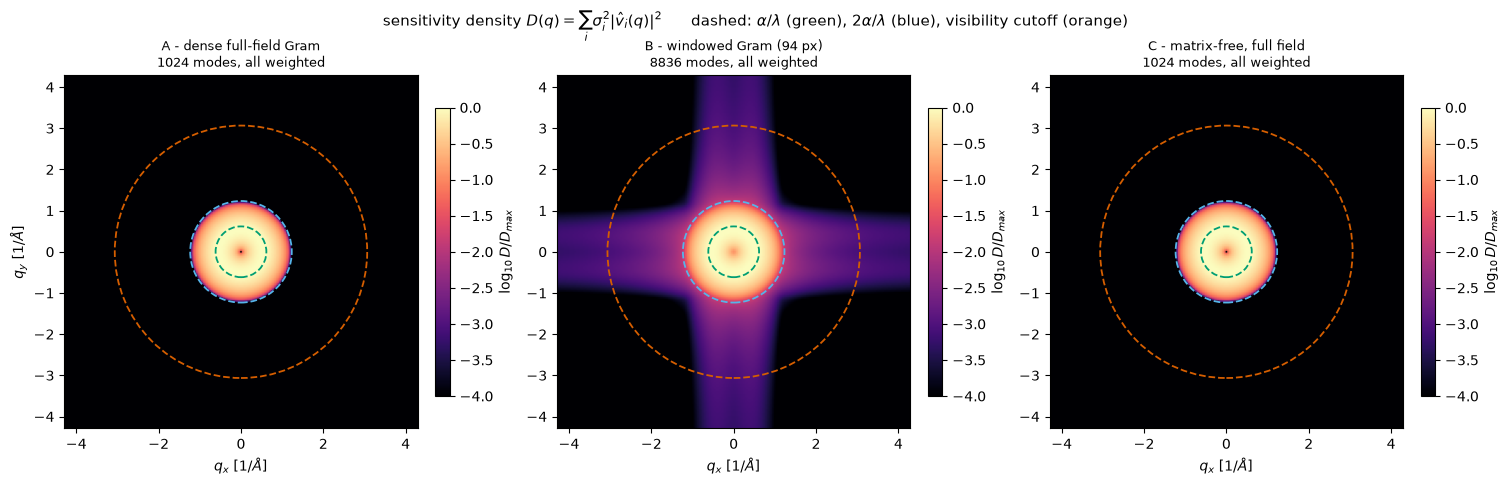

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.6), constrained_layout=True)
for column, key in enumerate(("A", "B", "C")):
    density = results[key]["density"]
    ax = axes[column]
    shown = np.log10(np.maximum(density / density.max(), 1e-6))
    handle = ax.imshow(shown, extent=frequency_extent, origin="lower", cmap="magma",
                       vmin=-4.0, vmax=0.0)
    for frequency, colour in [(aperture_radius_inv_ang, "#009E73"),
                              (2 * aperture_radius_inv_ang, "#56B4E9"),
                              (visibility_cutoff_inv_ang, "#D55E00")]:
        ax.add_patch(plt.Circle((0, 0), frequency, fill=False, edgecolor=colour,
                                linewidth=1.3, linestyle="--"))
    ax.set_xlim(-view, view); ax.set_ylim(-view, view)
    ax.set_xlabel("$q_x$ [1/$\\AA$]")
    if column == 0:
        ax.set_ylabel("$q_y$ [1/$\\AA$]")
    ax.set_title(f"{results[key]['name']}\n{len(results[key]['sigma'])} modes, all weighted",
                 fontsize=9)
    fig.colorbar(handle, ax=ax, shrink=0.8, label="$\\log_{10} D/D_{max}$")
fig.suptitle("sensitivity density $D(q)=\\sum_i \\sigma_i^2|\\hat v_i(q)|^2$"
             "      dashed: $\\alpha/\\lambda$ (green), $2\\alpha/\\lambda$ (blue), "
             "visibility cutoff (orange)", fontsize=11)
plt.show()

In [20]:
# what the k cap costs: method B has every mode, so it can answer this on its own.
window_sigma_all = results["B"]["sigma"]
n_cap = min(DENSE_N_MODES, len(window_sigma_all))
_, density_capped = weighted_mode_spectra(results["B"]["modes"][:n_cap],
                                          results["B"]["origin"], window_sigma_all[:n_cap])
density_capped_radial = angular_integral(density_capped)

print(f"method B, complete ({len(window_sigma_all)} modes) vs capped at k = {n_cap}")
print(f"   sum D  complete : {results['B']['density'].sum():.6e}   "
      f"(= ||A||_F^2 = {results['B']['frobenius']:.6e})")
print(f"   sum D  capped   : {density_capped.sum():.6e}   "
      f"({density_capped.sum() / results['B']['density'].sum():.4%} of it)")
print(f"   sigma_k/sigma_1 at the cap : {window_sigma_all[n_cap - 1] / window_sigma_all[0]:.4f}")

method B, complete (8836 modes) vs capped at k = 1024
   sum D  complete : 7.235733e-03   (= ||A||_F^2 = 7.235733e-03)
   sum D  capped   : 7.235466e-03   (99.9963% of it)
   sigma_k/sigma_1 at the cap : 0.0048


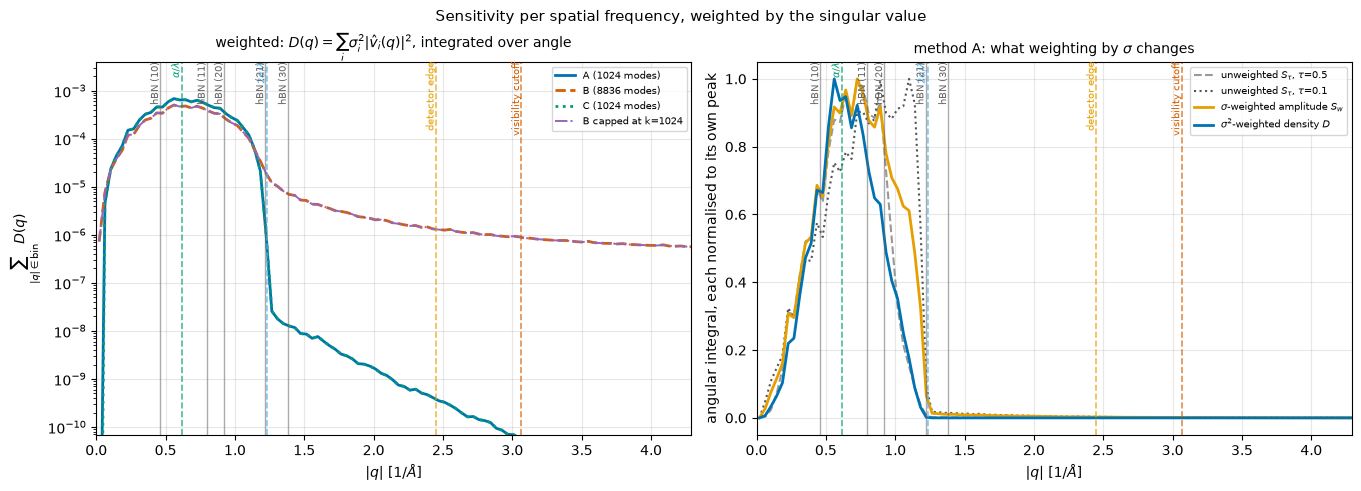

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), constrained_layout=True)

# ---- left: the weighted angular integral, all three methods -----------------
for key in ("A", "B", "C"):
    colour, dash = styles[key]
    axes[0].semilogy(radial_bin_centres_inv_ang, results[key]["density_radial"],
                     linestyle=dash, color=colour, linewidth=2.0,
                     label=f"{key} ({len(results[key]['sigma'])} modes)")
axes[0].semilogy(radial_bin_centres_inv_ang, density_capped_radial, linestyle="-.",
                 color="#9467bd", linewidth=1.4, label=f"B capped at k={n_cap}")
axes[0].set_ylabel("$\\sum_{|q|\\in \\mathrm{bin}} D(q)$")
axes[0].set_title("weighted: $D(q)=\\sum_i\\sigma_i^2|\\hat v_i(q)|^2$, integrated over angle",
                  fontsize=10)
floor = max(results["A"]["density_radial"].max() * 1e-7, 1e-30)
axes[0].set_ylim(floor, None)

# ---- right: what the weighting actually changed, on method A ----------------
curves = [(f"unweighted $S_\\tau$, $\\tau$={SIGMA_THRESHOLDS[0]}",
           results["A"]["radial"][SIGMA_THRESHOLDS[0]], "#999999", "--"),
          (f"unweighted $S_\\tau$, $\\tau$={SIGMA_THRESHOLDS[1]}",
           results["A"]["radial"][SIGMA_THRESHOLDS[1]], "#555555", ":"),
          ("$\\sigma$-weighted amplitude $S_w$",
           results["A"]["weighted_amplitude_radial"], "#E69F00", "-"),
          ("$\\sigma^2$-weighted density $D$",
           results["A"]["density_radial"], "#0072B2", "-")]
for label, profile, colour, dash in curves:
    axes[1].plot(radial_bin_centres_inv_ang, profile / profile.max(), linestyle=dash,
                 color=colour, linewidth=2.0 if dash == "-" else 1.5, label=label)
axes[1].set_ylabel("angular integral, each normalised to its own peak")
axes[1].set_title("method A: what weighting by $\\sigma$ changes", fontsize=10)

for ax in axes:
    for frequency, colour, label in [
        (aperture_radius_inv_ang, "#009E73", "$\\alpha/\\lambda$"),
        (2 * aperture_radius_inv_ang, "#56B4E9", "$2\\alpha/\\lambda$"),
        (detector_edge_inv_ang, "#E69F00", "detector edge"),
        (visibility_cutoff_inv_ang, "#D55E00", "visibility cutoff"),
    ]:
        ax.axvline(frequency, color=colour, linestyle="--", linewidth=1.2, alpha=0.7)
        ax.annotate(label, (frequency, ax.get_ylim()[1]), rotation=90, fontsize=7,
                    ha="right", va="top", color=colour)
    for label, frequency in lattice_reflections_inv_ang:
        if frequency > view:
            continue
        ax.axvline(frequency, color="#666666", linestyle="-", linewidth=1.0, alpha=0.55)
        ax.annotate(f"hBN {label}", (frequency, ax.get_ylim()[1]), rotation=90, fontsize=7,
                    ha="right", va="top", color="#666666")
    ax.set_xlim(0, view)
    ax.set_xlabel("$|q|$ [1/$\\AA$]")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
fig.suptitle("Sensitivity per spatial frequency, weighted by the singular value", fontsize=11)
plt.show()

In [22]:
# peak position and the |q| range over which a profile stays above half its peak
def half_power_band(profile):
    above = np.flatnonzero(profile >= 0.5 * profile.max())
    return (float(radial_bin_centres_inv_ang[int(np.argmax(profile))]),
            float(radial_bin_centres_inv_ang[above[0]]),
            float(radial_bin_centres_inv_ang[above[-1]]))


print(f"{'quantity':34s} {'peak':>8s} {'half-max band':>22s}   [1/A]")
for key in ("A", "B", "C"):
    for label, profile in [("unweighted $S$ tau=%.1f" % SIGMA_THRESHOLDS[1],
                            results[key]["radial"][SIGMA_THRESHOLDS[1]]),
                           ("sigma-weighted amplitude", results[key]["weighted_amplitude_radial"]),
                           ("sigma^2-weighted density", results[key]["density_radial"])]:
        peak, low, high = half_power_band(profile)
        print(f"{key + ' : ' + label:34s} {peak:8.3f} {low:10.3f} - {high:8.3f}")
    print()

print(f"   aperture alpha/lambda = {aperture_radius_inv_ang:.3f},  "
      f"2 alpha/lambda = {2 * aperture_radius_inv_ang:.3f},  "
      f"visibility cutoff = {visibility_cutoff_inv_ang:.3f} 1/A")
print("   hBN reflections [1/A] : "
      + ",  ".join(f"{label} {q:.3f}" for label, q in lattice_reflections_inv_ang))

fraction_below_aperture = {}
for key in ("A", "B", "C"):
    profile = results[key]["density_radial"]
    inside = radial_bin_centres_inv_ang <= aperture_radius_inv_ang
    fraction_below_aperture[key] = float(profile[inside].sum() / profile.sum())
print("\n   fraction of the total sensitivity below alpha/lambda:")
for key in ("A", "B", "C"):
    print(f"      {key}: {fraction_below_aperture[key]:.3%}")

quantity                               peak          half-max band   [1/A]
A : unweighted $S$ tau=0.1            1.100      0.436 -    1.183
A : sigma-weighted amplitude          0.726      0.353 -    1.100
A : sigma^2-weighted density          0.560      0.394 -    0.892

B : unweighted $S$ tau=0.1            1.100      0.560 -    1.224
B : sigma-weighted amplitude          0.726      0.394 -    1.141
B : sigma^2-weighted density          0.560      0.394 -    0.934

C : unweighted $S$ tau=0.1            1.100      0.436 -    1.183
C : sigma-weighted amplitude          0.726      0.353 -    1.100
C : sigma^2-weighted density          0.560      0.394 -    0.892

   aperture alpha/lambda = 0.617,  2 alpha/lambda = 1.233,  visibility cutoff = 3.065 1/A
   hBN reflections [1/A] : (10) 0.461,  (11) 0.799,  (20) 0.922,  (21) 1.220,  (30) 1.383

   fraction of the total sensitivity below alpha/lambda:
      A: 45.484%
      B: 43.892%
      C: 45.484%


### What the weighting changed, and the one artefact it exposed

**The content moves down in frequency, by a lot.** The angular integral peaks at
$1.100\ \mathrm{\AA^{-1}}$ unweighted at $\tau=0.1$, at $0.726$ once weighted by $\sigma$,
and at $0.560\ \mathrm{\AA^{-1}}$ weighted by $\sigma^2$ - just inside $\alpha/\lambda =
0.617$. The half-maximum band of $D$ is $0.39$-$0.89\ \mathrm{\AA^{-1}}$, and $45\%$ of the
whole sensitivity budget sits below $\alpha/\lambda$ alone. The unweighted plot was
reporting the *reach* of the retained subspace; the weighted one reports where the
experiment actually responds, and those are different statements about a different
quantity. For a dose or detectability argument it is $D$ that enters, so the earlier
curves should not be quoted as sensitivity.

**The $k$ cap turns out to be irrelevant to $D$.** B's complete spectrum and B capped at
$k=1024$ give the same total to within $4\times10^{-5}$ ($99.9963\%$), even though the cap
discards $7812$ of $8836$ modes, because at the cut $\sigma_k/\sigma_1 = 0.0048$ and the
weight is $\sigma^2$. The full-field $D$ from methods A and C is therefore effectively
exact, not a lower bound in any meaningful sense - which is worth stating, because it means
the top-$k$ restriction that makes the full field tractable costs nothing on the quantity
that matters.

**The one thing that does differ is an artefact of method B.** In the maps, A and C are
clean isotropic discs that stop at $\approx 1.23\ \mathrm{\AA^{-1}}$, while B carries a
bright cross along $q_x$ and $q_y$ out to the edge of the plot, four decades above the
full-field tail. That cross is not sensitivity: it is spectral leakage from the window's
hard square edge, the separable $\mathrm{sinc}$ of a boxcar. The control proves it -
capping B at $k=1024$ leaves the cross untouched, so it is not the discarded weak modes
either. Read as physics it would suggest the window retains high-frequency sensitivity the
full field has lost, which is backwards. **Any use of the window method for a frequency
argument needs an apodised window, or the cross has to be masked.** The window is sound for
eigenvalues - Cauchy interlacing still holds - but its *spectra* are contaminated along the
axes.

**The cliff is optical, not crystallographic.** Both weighted and unweighted curves fall
off a cliff at $\approx 1.23\ \mathrm{\AA^{-1}}$, which is $2\alpha/\lambda = 1.233$: the
largest spatial frequency at which two points of the bright-field disc still overlap, and
so the last frequency that can interfere onto the camera at all. The hBN $(21)$ reflection
sits at $1.220\ \mathrm{\AA^{-1}}$, within $1\%$ of it, and a plot carrying only the
lattice annotation invites exactly the wrong reading. The $2\alpha/\lambda$ line is drawn
on these panels for that reason. The position is a property of the aperture, and the way
to confirm it is to change $\alpha$ and watch the cliff move - which is what notebook 01's
sweep is for.

## Summary

In [23]:
print(f"{'method':36s} {'domain [px]':>13s} {'modes':>8s} {'complete':>9s} "
      f"{'sigma_1':>12s} {'time [s]':>9s}")
for key in ("A", "B", "C"):
    result = results[key]
    print(f"{result['name']:36s} {result['n_domain']:13,d} {len(result['sigma']):8d} "
          f"{str(result['complete']):>9s} {result['sigma'][0]:12.4e} {result['seconds']:9.1f}")
print()
for key in ("A", "B", "C"):
    print(f"   {key}: {results[key]['notes']}")
print()
print(f"scan            : {scan_shape} = {n_scan_positions} positions at "
      f"{realised_scan_step_ang:.3f} A over {SCAN_REGION_START} to {SCAN_REGION_END} A")
print(f"band limits     : aperture {aperture_radius_inv_ang:.3f}, detector edge "
      f"{detector_edge_inv_ang:.3f}, visibility cutoff {visibility_cutoff_inv_ang:.3f}, "
      f"object Nyquist {object_nyquist_inv_ang:.3f} 1/A")
print(f"interlacing     : max B/A = {ratio_b.max():.6f}, max C/A = {ratio_c.max():.6f} "
      f"(both must be <= 1)")

method                                 domain [px]    modes  complete      sigma_1  time [s]
A - dense full-field Gram                   63,001     1024     False   6.5109e-03     705.2
B - windowed Gram (94 px)                    8,836     8836      True   6.5050e-03       6.5
C - matrix-free, full field                 63,001     1024     False   6.5109e-03     143.2

   A: float32, 1024 of 63,001 modes
   B: float64, complete spectrum
   C: no Gram, 1024 of 63,001 modes

scan            : (20, 20) = 400 positions at 0.500 A over (7.0, 7.0) to (17.0, 17.0) A
band limits     : aperture 0.617, detector edge 2.449, visibility cutoff 3.065, object Nyquist 5.208 1/A
interlacing     : max B/A = 0.999090, max C/A = 1.000048 (both must be <= 1)


## How to read this

* **The spectrum has two blind ends, not one.** A spatially constant phase is exactly null -
  for constant $\Delta\varphi$ the perturbation wave is $\Psi_\Delta = \Delta\varphi\,\Psi_0$
  and $\mathrm{Im}(\Delta\varphi|\Psi_0|^2) = 0$ - and so is everything above the visibility
  cutoff $q_{\max} + \alpha/\lambda$. The scan is a band-pass on object phase, and its pass
  band is what any reconstruction from this geometry can contain.

* **Sensitivity peaks near the aperture frequency, not at zero.** The leading modes sit at
  $\bar q \sim \alpha/\lambda$ rather than at low frequency, because that is where the
  scattered wave interferes with the bright-field disc over the largest area. This is the
  standard ptychographic transfer argument arriving as a property of the operator rather than
  as an assumption.

* **Check the seed-overlap panel before reading any individual mode picture.** The top of
  the spectrum is crowded, and if a cluster were exactly degenerate its vectors would be an
  arbitrary basis fixed by the random seed. The overlap between two independently seeded
  runs is what distinguishes that from merely close-but-resolved singular values. Where the
  overlap is 1 the pictures can be read; where it falls away, read $\sigma_i$, $\bar q_i$
  and the mode-sum spectrum $S_\tau(q)$ instead, since those are properties of the subspace
  rather than of the basis chosen inside it.

* **The window does not approximate the full field, it answers a different question.** It
  asserts that the perturbation vanishes outside the window, so it is the right calculation
  for a localized excitation and the wrong one for an extended one. Cauchy interlacing says
  its answer is a lower bound on the full-field one; how tight that bound is depends on how
  well the modes in question fit inside the window, which is what the $B/A$ curve measures.

* **The count of modes above a numerical floor is a statement about arithmetic, not physics.**
  Forming the Gram costs half the digits, so sections A and B report the spectrum down to
  $10^{-5}$ and $10^{-8}$ of $\sigma_1$ respectively and no further. Read the position of the
  roll-off in $\bar q$, which is stable, rather than the exact rank.

* **The scan's own bookkeeping is part of the operator.** Duplicate positions and uneven
  coverage both re-weight $A^{\mathsf T}A$, and the leading modes report that weighting before
  they report anything about the optics. The coverage panel is there to be checked first.

### What this does not establish

Every singular value here describes a *noiseless* measurement: the small ones are the
directions a perfect detector could not separate. Adding Poisson noise at a finite dose
raises the effective floor far above the numerical one, so the practically blind subspace is
much larger than the null space of $A$. Turning this spectrum into a statement about what a
real experiment can detect needs the dose and the noise covariance - the conditional Fisher
information $A^{\mathsf T}\Sigma^{-1}A$ rather than $A^{\mathsf T}A$ - and, beyond that, the
nuisance parameters of the base state, which remove from the identifiable subspace anything
a correction to the object, probe or scan positions could imitate. Both belong in their own
notebook.